# **SegFormer-B0 для DLR SkyScapes-Dense: инференс, оценка и дообучение (MMSegmentation 1.2.2)**

Автономный блокнот: всё нужное он разворачивает сам, заранее ничего загружать не надо. Все файлы скачиваются и сохраняются только на локальный диск сессии Colab (`/content`). Исходный код и релиз с весами: https://github.com/tester170/skyscapes-segformer-b0.

Откуда берутся файлы:
* **код конвейера** (конфигурация, датасет, аугментации, метрики, хуки, скрипты) — клонируется из репозитория GitHub на метке релиза `v1.0`;
* **обученная модель** (SegFormer-B0, эпоха 220), **кодировщик LoveDA** (только для обучения заново) и **MMCV 2.1.0** — файлы релиза `v1.0`, каждый проверяется по контрольной сумме;
* **окружение** — Python 3.11, PyTorch 2.1.0 + CUDA 12.1, MMEngine 0.10.7, MMSegmentation 1.2.2 с точными версиями эксперимента — ставится из PyPI и PyTorch отдельно от окружения Colab;
* **набор DLR SkyScapes** (`SS_Dense`) — из релиза, если он там есть, иначе с официального сервера DLR; в обоих случаях с проверкой контрольной суммы.

Блокнот выполняет инференс по снимкам любого размера (JPG/PNG/GeoTIFF и другие растры) с полноразмерными масками, оценку на валидационной выборке со всеми метриками и матрицами ошибок по всем уровням укрупнения классов, дообучение и обучение заново той же схемой, что в эксперименте.

Для запуска выберите *Среда выполнения → Сменить среду выполнения → GPU* (T4 достаточно), затем *Среда выполнения → Выполнить все*. До готовности к инференсу проходит около 5 минут. Обучение по умолчанию выключено (`TRAIN` в разделе 5). В конце блокнот предложит выбрать свой снимок (раздел 7) и покажет кнопки скачивания весов и результатов (раздел 8).

Тестовая выборка SkyScapes опубликована без эталонной разметки, поэтому качество оценивается по валидационной выборке.

## **Параметры и загрузка пакета**

Пути ниже указывают на локальный диск сессии. Он очищается при её завершении, поэтому нужные результаты скачайте кнопками раздела 8 или из панели «Файлы» слева.

In [1]:
import os, sys, json
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO   = 'tester170/skyscapes-segformer-b0'           # репозиторий GitHub с кодом и релизом
TAG    = 'v1.0'                                 # версия (метка релиза)
ROOT   = os.environ.get('SKY_ROOT', '/content')       # локальный диск сессии Colab
BUNDLE = f'{ROOT}/skyscapes_segformer'                # код и модель (из репозитория)
DATA   = f'{ROOT}/data/SS_Dense'                      # набор SkyScapes (скачивается)
WORK   = f'{ROOT}/skyscapes_segformer_runs'           # результаты
CACHE  = f'{ROOT}/cache'                              # кэш декодированных снимков
ENV    = f'{ROOT}/py311'                              # окружение Python 3.11
PY = f'{ENV}/bin/python'


def run(*args):
    # команда с выводом в реальном времени; при ошибке ячейка останавливается
    import subprocess
    env = {**os.environ, 'MPLBACKEND': 'Agg', 'PYTHONUNBUFFERED': '1'}
    p = subprocess.Popen([str(a) for a in args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError(f'команда завершилась с ошибкой (код {p.returncode}): ' + ' '.join(map(str, args)))


def download_button(label, make_file):
    # кнопка: по нажатию файл готовится (make_file() возвращает путь) и скачивается браузером
    import ipywidgets as widgets
    from IPython.display import display
    out = widgets.Output()
    button = widgets.Button(description=label, icon='download', button_style='primary', layout=widgets.Layout(width='auto'))

    def click(_):
        with out:
            path = make_file()
            print(f'{Path(path).name}: {Path(path).stat().st_size / 2 ** 20:.1f} МБ')
            if IN_COLAB:
                from google.colab import files
                files.download(path)

    button.on_click(click)
    display(widgets.VBox([button, out]))


def zip_folder(folder, name):
    import shutil
    return shutil.make_archive(f'{ROOT}/{name}', 'zip', folder)


Path(WORK).mkdir(parents=True, exist_ok=True)
print('пакет    :', BUNDLE)
print('данные   :', DATA)
print('результат:', WORK)

пакет    : /content/skyscapes_segformer
данные   : /content/data/SS_Dense
результат: /content/skyscapes_segformer_runs


Следующая ячейка клонирует код из репозитория на метке релиза и скачивает из релиза обученную модель (15 МБ) с проверкой контрольной суммы.

In [2]:
if not Path(BUNDLE, 'scripts', 'infer.py').exists():
    run('git', 'clone', '--quiet', '--depth', '1', '--branch', TAG, f'https://github.com/{REPO}.git', BUNDLE)
run('python3', f'{BUNDLE}/scripts/fetch.py', 'model')
CHECKPOINT = f'{BUNDLE}/checkpoints/segformer_b0_skyscapes_ep220.pth'

Note: switching to '42858aaefa308a839d974e07012901b287c97294'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

segformer_b0_skyscapes_ep220.pth (14 MB) from tester170/skyscapes-segformer-b0 release v1.0
  segformer_b0_skyscapes_ep220.pth: 4/14 MB (52.9 MB/s)
  segformer_b0_skyscapes_ep220.pth: 8/14 MB (67.4 MB/s)
  segformer_b0_skyscapes_ep220.pth: 12/14 MB (53.7 MB/s)
  segformer_b0_skyscapes_ep220.pth: 14/14 MB (49.9 MB/s)


## **1. Рабочее окружение**

Создаётся отдельное окружение Python 3.11 со строго зафиксированными версиями всех пакетов (`env/requirements.lock`, установка без подбора зависимостей). Первый запуск занимает 3–5 минут; повторный запуск в той же сессии ничего не переустанавливает.

MMCV 2.1.0 — официальная сборка OpenMMLab для torch 2.1 и CUDA 12.1 — берётся из релиза проекта, при его недоступности с сервера OpenMMLab; если недоступны оба, MMCV собирается из исходников, это около 30 минут.

В конце проверяются версии пакетов, GPU и CUDA-операции MMCV.

In [3]:
run('bash', f'{BUNDLE}/env/setup_env.sh', ENV)

== installing uv (Python and package installer)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 99.7 MB/s eta 0:00:00
== creating Python 3.11 environment in /content/py311
Using CPython 3.11.17
Creating virtual environment with seed packages at: py311
 + packaging==26.3
 + pip==26.2.1
 + setuptools==84.0.0
 + wheel==0.48.0
Activate with: source py311/bin/activate
== installing pinned packages (PyTorch 2.1.0 cu121, MMEngine, MMSegmentation, ...): ~2-3 min
Using Python 3.11.17 environment at: py311
Resolved 62 packages in 653ms
Prepared 60 packages in 45.84s
Uninstalled 1 package in 38ms
Installed 60 packages in 609ms
 + addict==2.4.0
 + affine==3.0.1
 + attrs==26.1.0
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + click==8.5.0
 + click-plugins==1.1.1.2
 + cligj==0.7.2
 + cloudpickle==3.1.2
 + contourpy==1.3.3
 + cycler==0.12.1
 + filelock==4.2.0
 + fonttools==4.67.0
 + fsspec==2026.9.0
 + ftfy==6.3.1
 + idna==3.20
 + jinja2==3.1.6
 + kiwisolver==1.5.1
 + llvmlite==0.43.0


## **2. Набор DLR SkyScapes**

Используется часть `SS_Dense` набора DLR SkyScapes (страница набора: https://www.dlr.de/en/eoc/about-us/remote-sensing-technology-institute/photogrammetry-and-image-analysis/public-datasets/dlr-skyscapes) с обучающей, валидационной и тестовой выборками. Архив берётся из релиза проекта, если он там есть, иначе с официального сервера DLR; контрольная сумма проверяется в обоих случаях.

При использовании набора авторы просят ссылаться на статью: S. Azimi et al., *SkyScapes — Fine-Grained Semantic Understanding of Aerial Scenes*, ICCV 2019.

Затем снимки обучающей и валидационной выборок один раз декодируются в кэш на локальном диске; это занимает меньше минуты.

In [4]:
if not Path(DATA, 'val', 'images').exists():
    run('python3', f'{BUNDLE}/scripts/fetch.py', 'dataset', '--out', str(Path(DATA).parent))
run(PY, f'{BUNDLE}/scripts/prepare_data.py', '--data', DATA, '--cache', CACHE)

data_dense.zip (144 MB) from tester170/skyscapes-segformer-b0 release v1.0
  attempt 1/3 failed: HTTP Error 404: Not Found
release unavailable (HTTP Error 404: Not Found); official DLR archive https://pba-freesoftware.eoc.dlr.de/SkyScapes.zip
  SkyScapes.zip: 4/275 MB (2.7 MB/s)
  SkyScapes.zip: 32/275 MB (8.9 MB/s)
  SkyScapes.zip: 60/275 MB (9.3 MB/s)
  SkyScapes.zip: 88/275 MB (9.5 MB/s)
  SkyScapes.zip: 116/275 MB (9.8 MB/s)
  SkyScapes.zip: 144/275 MB (9.9 MB/s)
  SkyScapes.zip: 172/275 MB (10.0 MB/s)
  SkyScapes.zip: 200/275 MB (10.2 MB/s)
  SkyScapes.zip: 228/275 MB (10.4 MB/s)
  SkyScapes.zip: 256/275 MB (10.7 MB/s)
  SkyScapes.zip: 275/275 MB (11.0 MB/s)
dataset ready: /content/data/SS_Dense (images {'train': 8, 'val': 2, 'test': 6})
train/2012-04-26-Muenchen-Tunnel_4K0G0010: cached in 0.6 s
train/2012-04-26-Muenchen-Tunnel_4K0G0020: cached in 0.6 s
train/2012-04-26-Muenchen-Tunnel_4K0G0030: cached in 0.8 s
train/2012-04-26-Muenchen-Tunnel_4K0G0051: cached in 0.6 s
train/2012-

## **3. Инференс по валидационной выборке**

Модель обрабатывает снимки валидационной выборки и сравнивает маски с эталонной разметкой. Предсказание выполняется так же, как на валидации при обучении: скользящее окно 1024 × 1024 с шагом 768 на исходном разрешении.

Для каждого снимка сохраняются:
* `<имя>_classes` — коды классов 1…20 в кодировке `labels/grayscale` набора;
* `<имя>_color` — цветная маска в палитре набора и `<имя>_preview.jpg` — снимок рядом с маской;
* `<имя>_L<n>_classes` и `_color` — маски укрупнённых схем из `SCHEMES` (легенда кодов — `schemes_legend.json`);
* `<имя>_conf` — карта уверенности (при `CONF = True`).

Для георастров маски записываются в GeoTIFF с той же проекцией, привязкой и встроенной палитрой (в QGIS цвета классов видны сразу), для обычных снимков — в PNG.

In [5]:
INPUT      = os.environ.get('SKY_INFER_INPUT', f'{DATA}/val/images')    # файл или папка
OUT_INFER  = f'{WORK}/inference'
SCHEMES    = '9 6 5'          # укрупнённые схемы (число классов), '' — не нужны
CONF       = True             # сохранить карту уверенности
LABELS     = f'{DATA}/val/labels/grayscale'                               # '' — без оценки

args = ['--input', INPUT, '--out', OUT_INFER, '--checkpoint', CHECKPOINT]   # CHECKPOINT — модель из релиза или свой best_mIoU_epoch_*.pth
args += ['--schemes', *SCHEMES.split()] if SCHEMES else []
args += ['--conf'] if CONF else []
args += ['--labels', LABELS, '--plot'] if LABELS and Path(LABELS).exists() else []
run(PY, f'{BUNDLE}/scripts/infer.py', *args)

GPU Tesla T4: free 14.5 of 14.6 GB
/content/py311/lib/python3.11/site-packages/mmseg/models/builder.py:36: UserWarning: ``build_loss`` would be deprecated soon, please use ``mmseg.registry.MODELS.build()`` 
  warnings.warn('``build_loss`` would be deprecated soon, please use '
/content/py311/lib/python3.11/site-packages/mmseg/models/losses/cross_entropy_loss.py:250: UserWarning: Default ``avg_non_ignore`` is False, if you would like to ignore the certain label and average loss over non-ignore labels, which is the same with PyTorch official cross_entropy, set ``avg_non_ignore=True``.
  warnings.warn(
2012-04-26-Muenchen-Tunnel_4K0G0110.jpg: 5616x3744 -> masks in 7.3 s | mIoU(20) 35.80
2012-04-26-Muenchen-Tunnel_4K0G0130.jpg: 5616x3744 -> masks in 6.8 s | mIoU(20) 36.61
all labelled images: {'mIoU': 36.3289, 'kappa': 0.7357, 'OA': 77.9767, 'mDice': 47.6586, 'mIoU_S9': 62.5938, 'mIoU_S6': 73.9245, 'mIoU_S5': 78.968}
16 matrices + curves -> /content/skyscapes_segformer_runs/inference/figur

2012-04-26-Muenchen-Tunnel_4K0G0110_preview.jpg


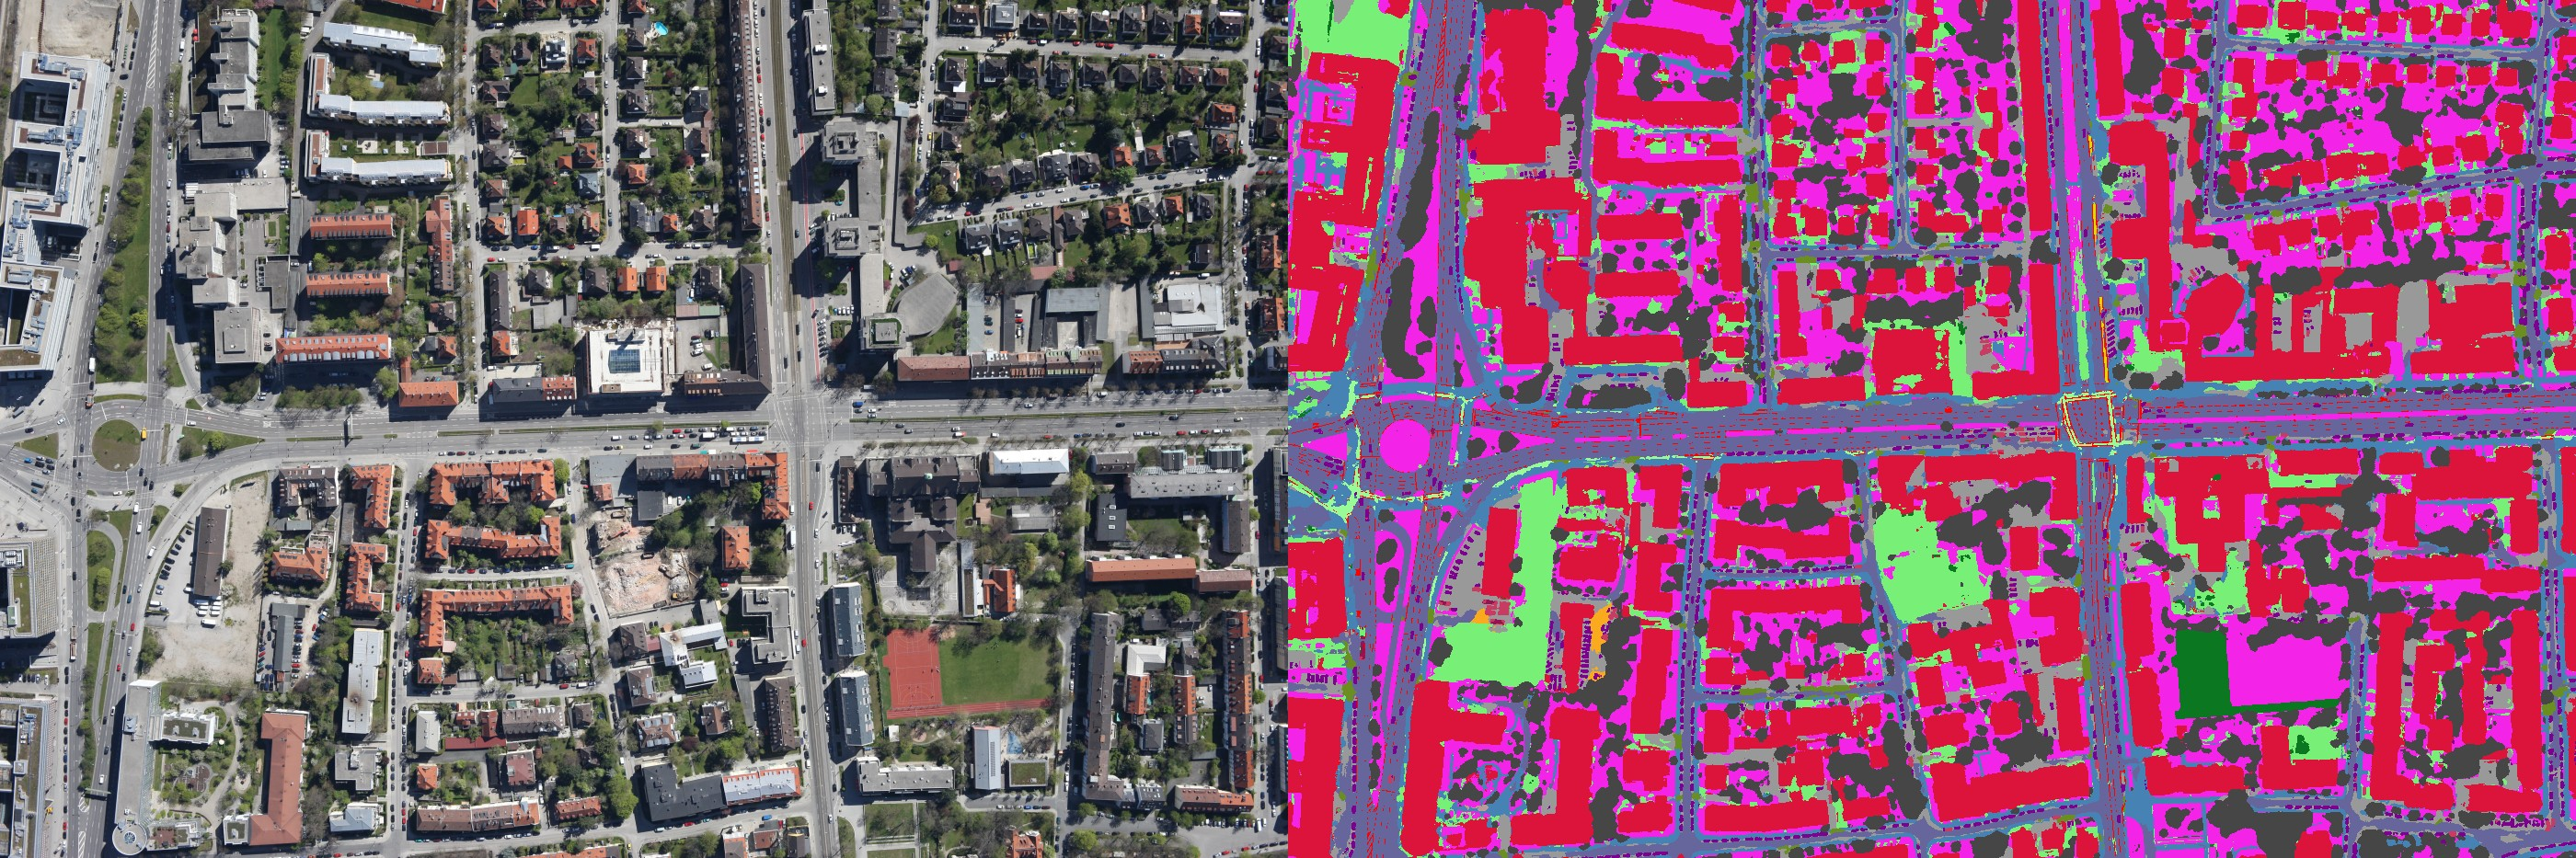

2012-04-26-Muenchen-Tunnel_4K0G0130_preview.jpg


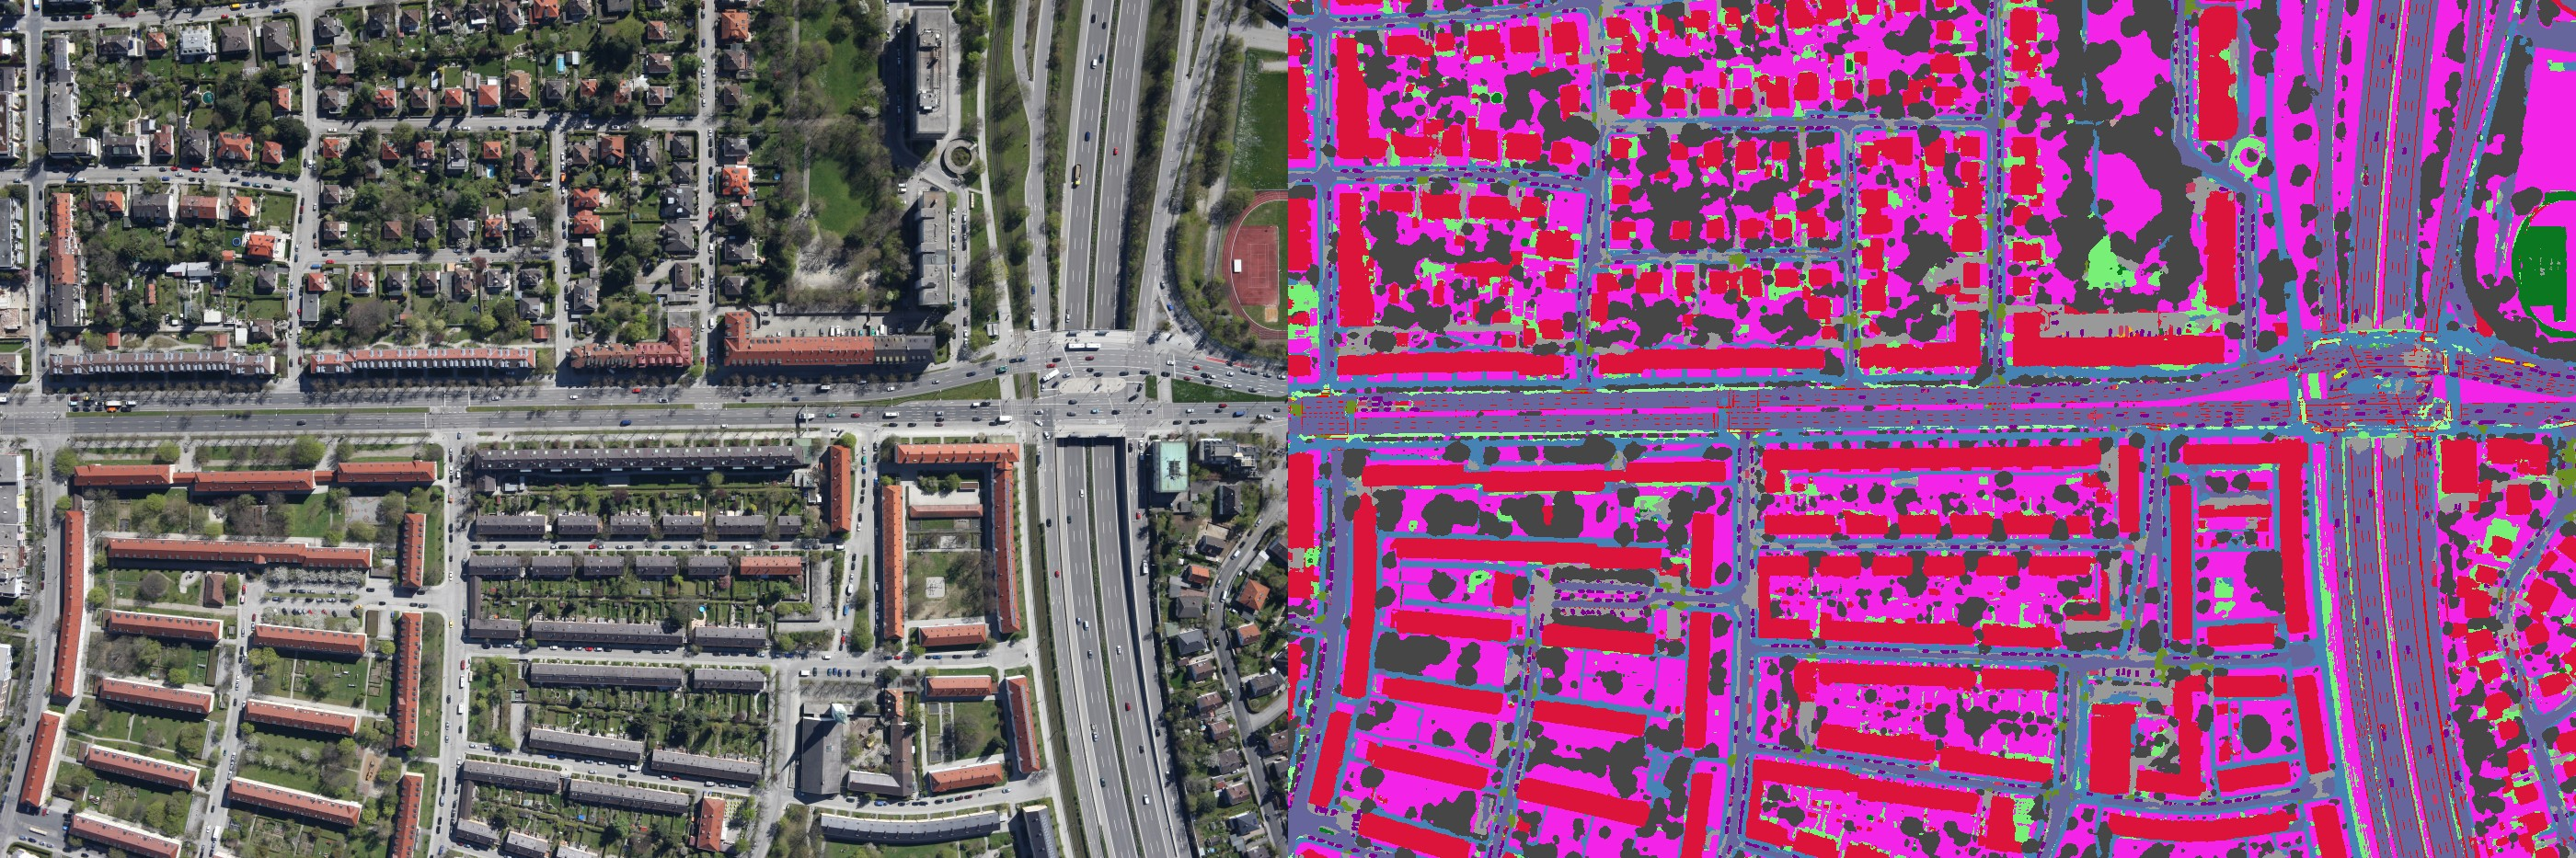

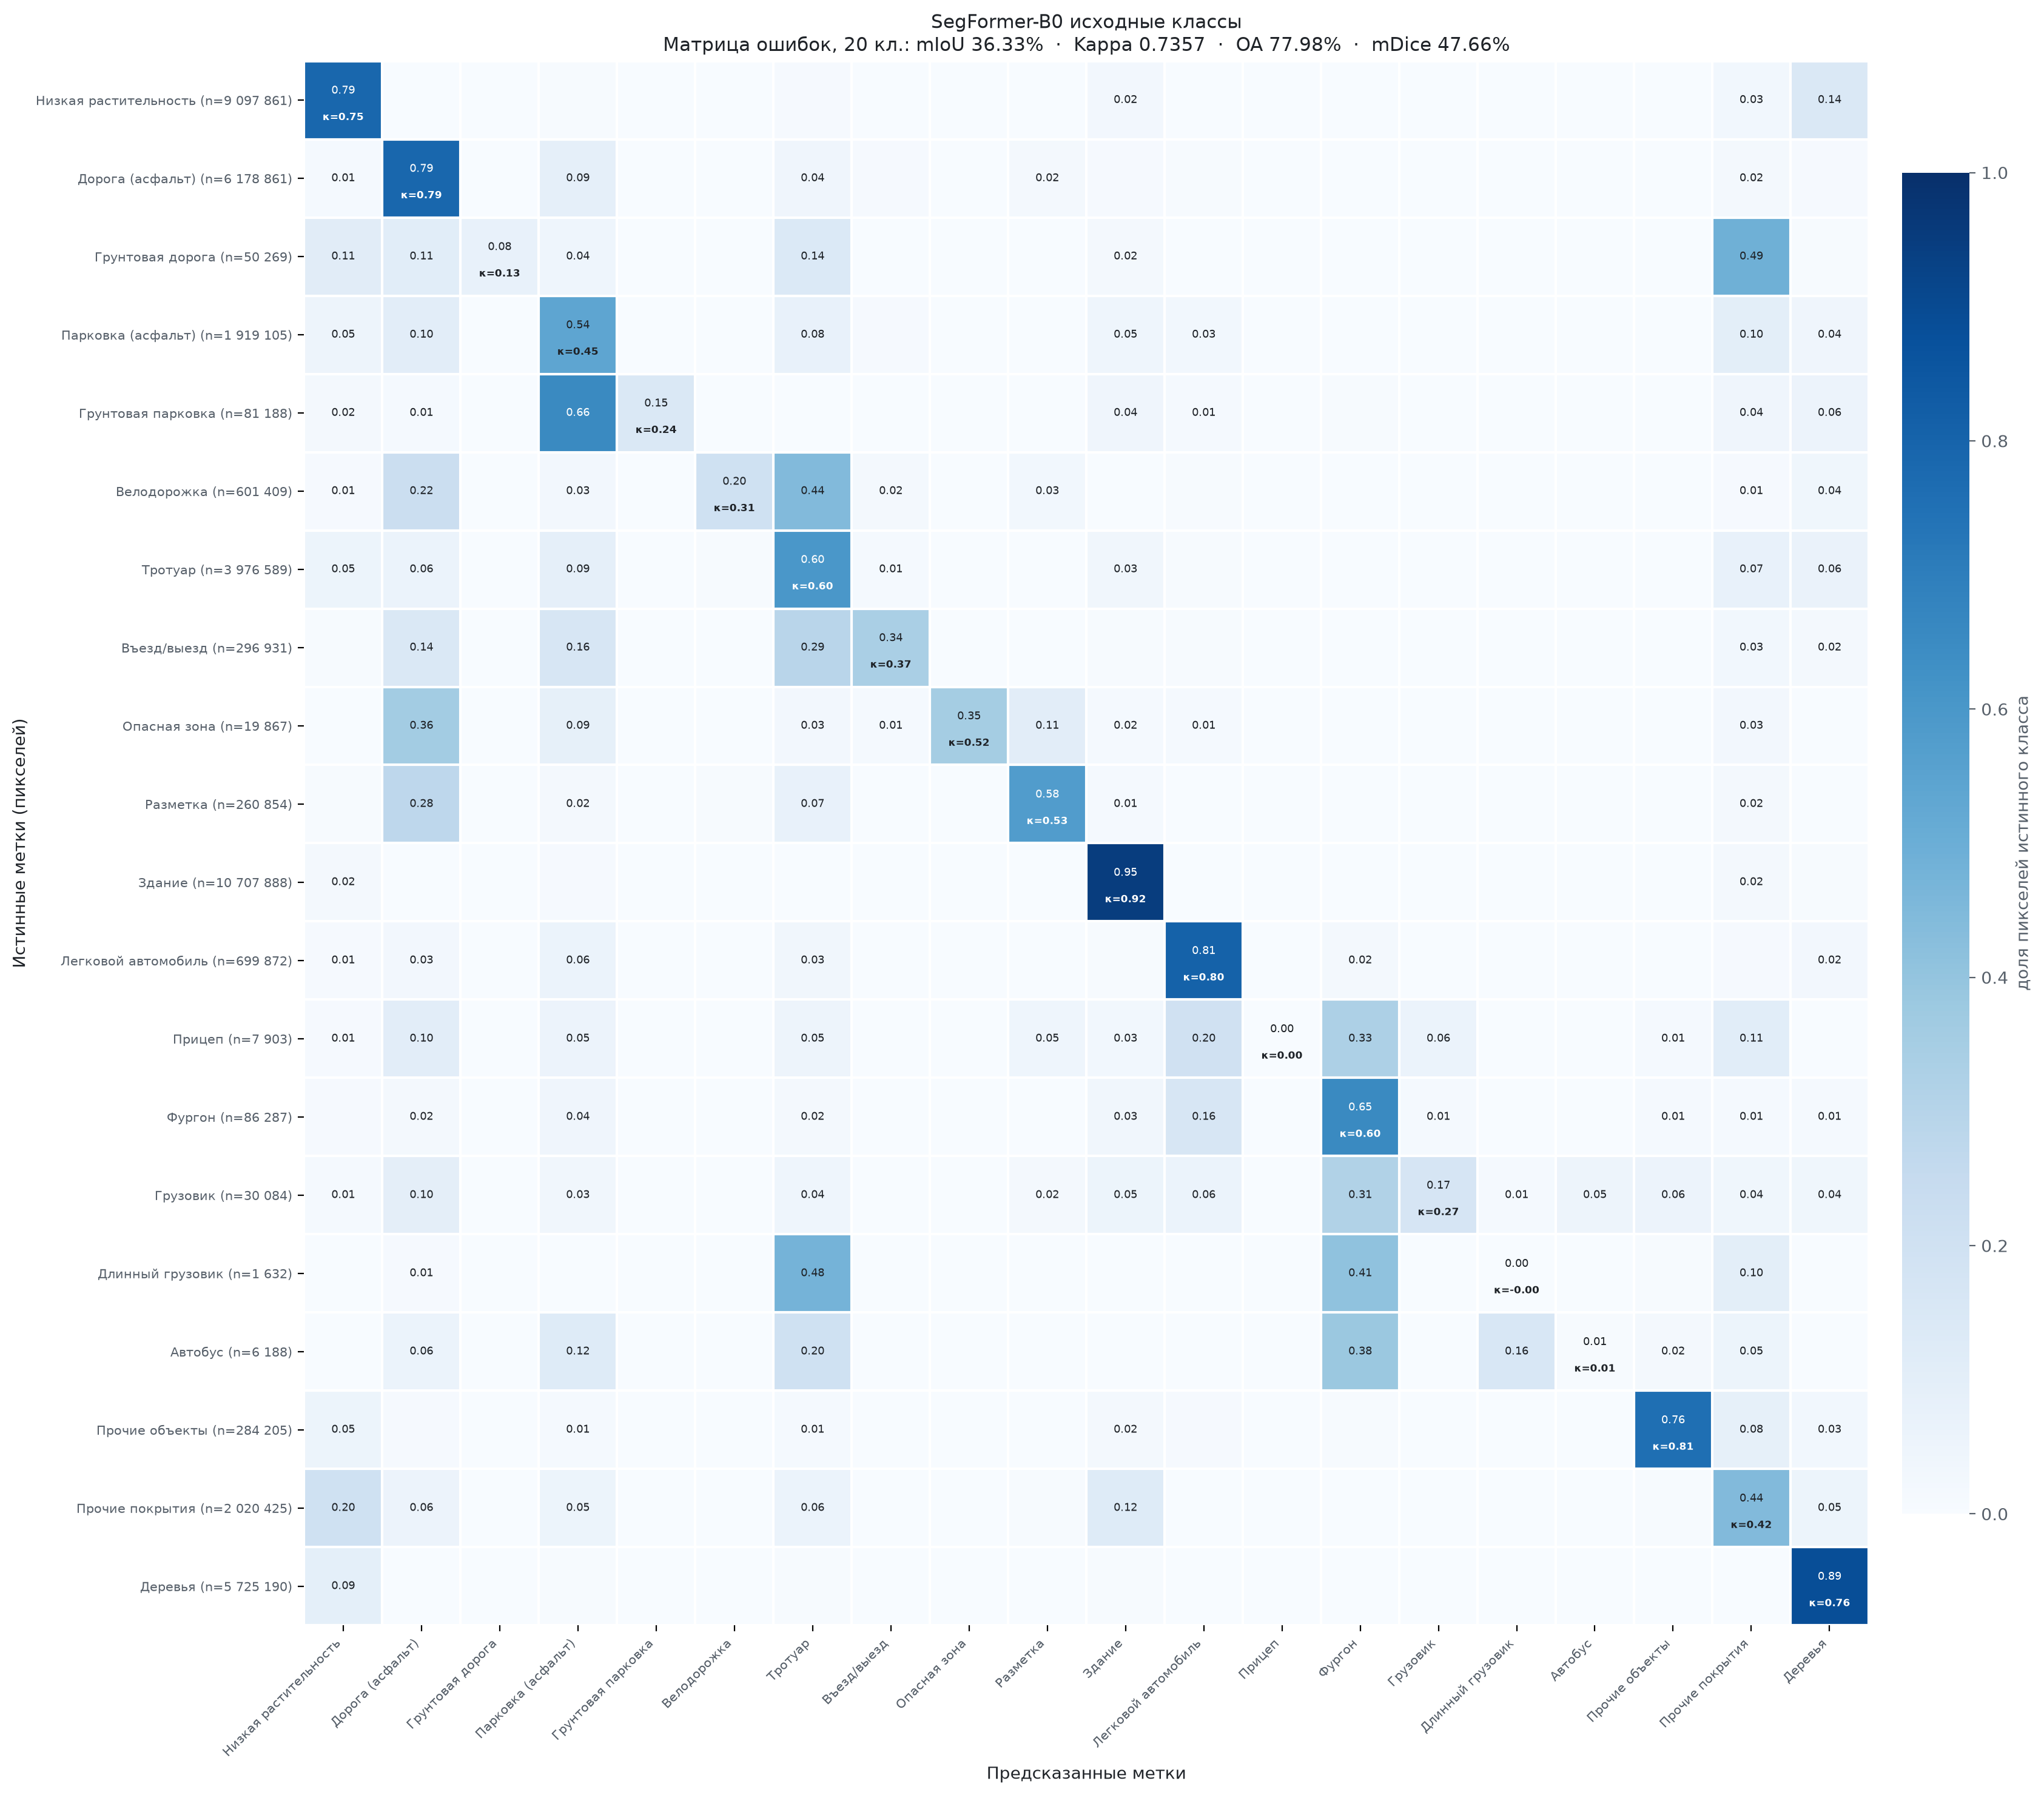

In [6]:
from IPython.display import Image, display
for p in sorted(Path(OUT_INFER).glob('*_preview.jpg'))[:3]:
    print(p.name); display(Image(str(p), width=1100))
fig = Path(OUT_INFER, 'figures', 'cm_L0_20.png')
if fig.exists():
    display(Image(str(fig), width=1100))

## **4. Оценка модели на валидационной выборке**

Считаются все метрики — IoU, Dice/F1, Precision, Recall, Kappa, MCC, OA по классам и средние — для 20 классов и для каждого шага укрупнения 20 → 5 классов. Матрицы ошибок (200 dpi, κ класса на диагонали) сохраняются в папку `figures`.

Ожидаемый результат для модели из релиза: mIoU 36,33 % на 20 классах, κ = 0,736.

In [7]:
EVAL_CKPT = CHECKPOINT
OUT_EVAL  = f'{WORK}/evaluation'
run(PY, f'{BUNDLE}/scripts/evaluate.py', '--cache', CACHE, '--checkpoint', EVAL_CKPT, '--out', OUT_EVAL)

GPU Tesla T4: free 14.5 of 14.6 GB
10/16 19:34:04 - mmengine - INFO - 
------------------------------------------------------------
System environment:
    sys.platform: linux
    Python: 3.11.17 (main, Oct 14 2026, 01:05:33) [Clang 23.1.3 ]
    CUDA available: True
    MUSA available: False
    numpy_random_seed: 0
    GPU 0: Tesla T4
    CUDA_HOME: /usr/local/cuda
    NVCC: Cuda compilation tools, release 13.0, V13.0.88
    GCC: cc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
    PyTorch: 2.1.0+cu121
    PyTorch compiling details: PyTorch built with:
  - GCC 9.3
  - C++ Version: 201703
  - Intel(R) oneAPI Math Kernel Library Version 2022.2-Product Build 20220804 for Intel(R) 64 architecture applications
  - Intel(R) MKL-DNN v3.1.1 (Git Hash 64f6bcbcbab628e96f33a62c3e975f8535a7bde4)
  - OpenMP 201511 (a.k.a. OpenMP 4.5)
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: AVX512
  - CUDA Runtime 12.1
  - NVCC architecture flags: -gencode;arch=comp

20 классов: mIoU 36.33 %, mDice 47.66 %, OA 77.98 %, kappa 0.7357, val loss 0.809
mIoU по числу классов: {20: 36.3, 19: 37.7, 18: 39.8, 17: 42.2, 16: 44.9, 15: 47.1, 14: 48.1, 13: 51.3, 12: 54.5, 11: 57.5, 10: 59.9, 9: 62.6, 8: 64.9, 7: 70.2, 6: 73.9, 5: 79.0}


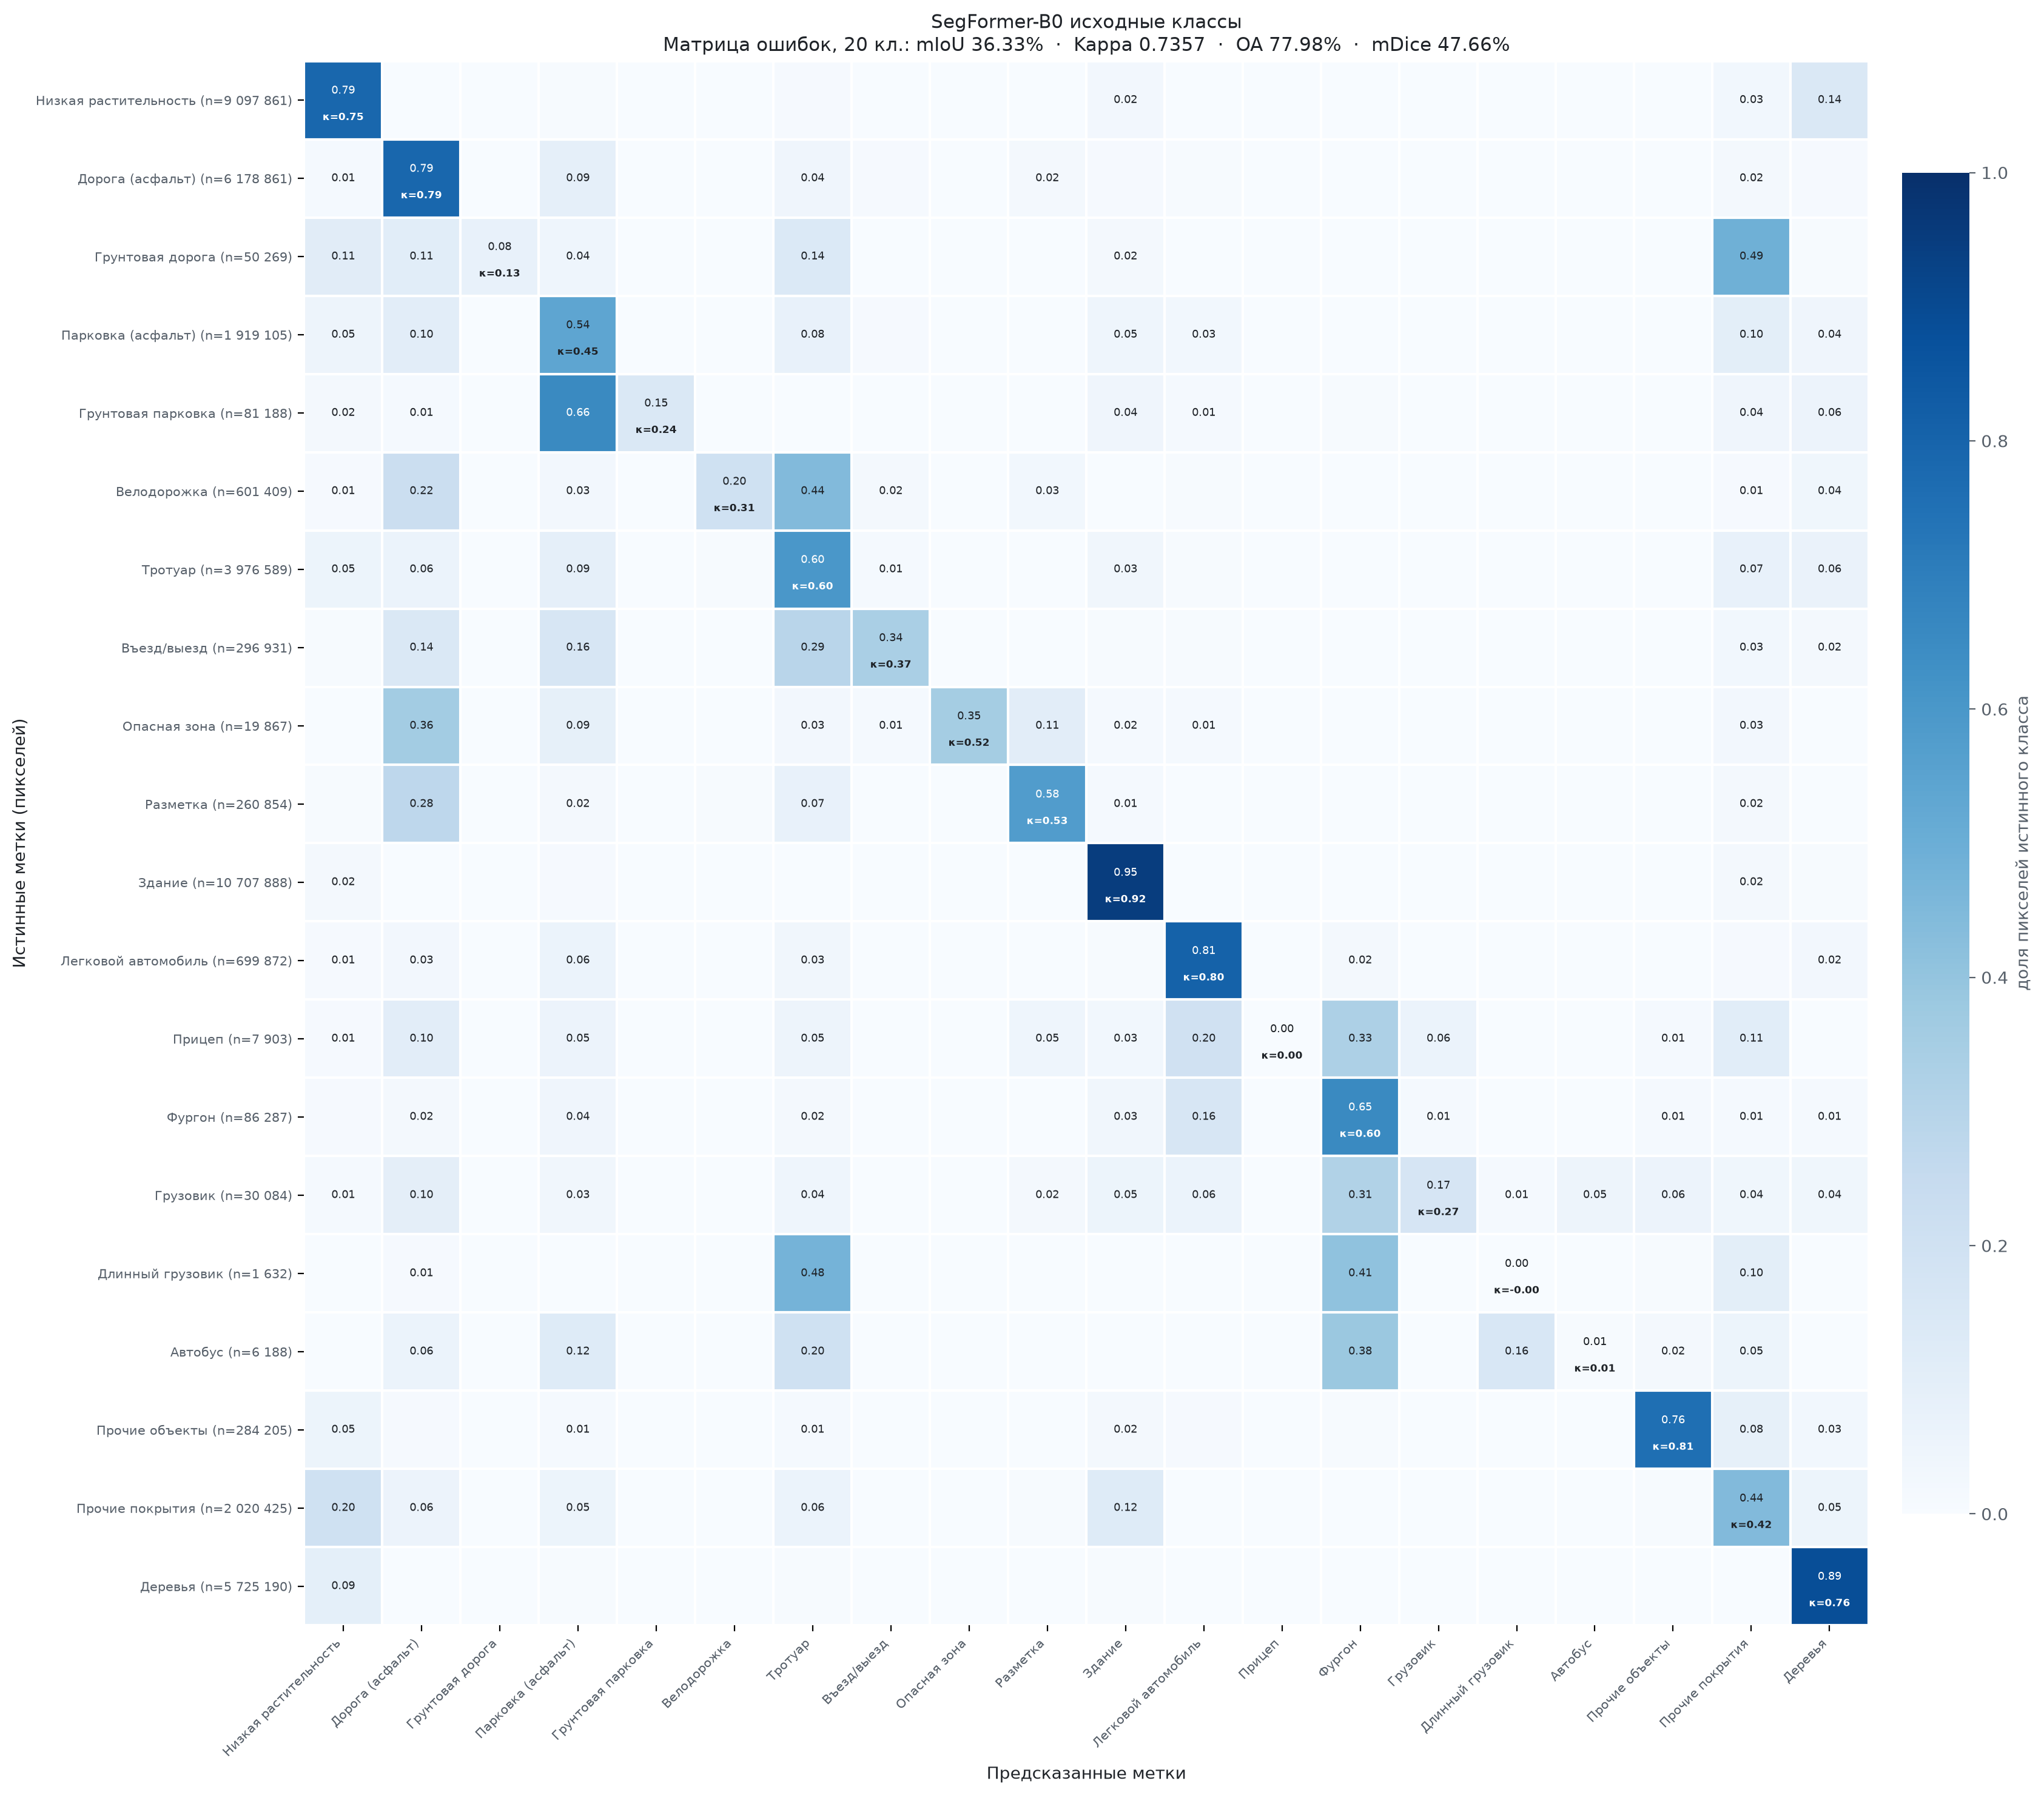

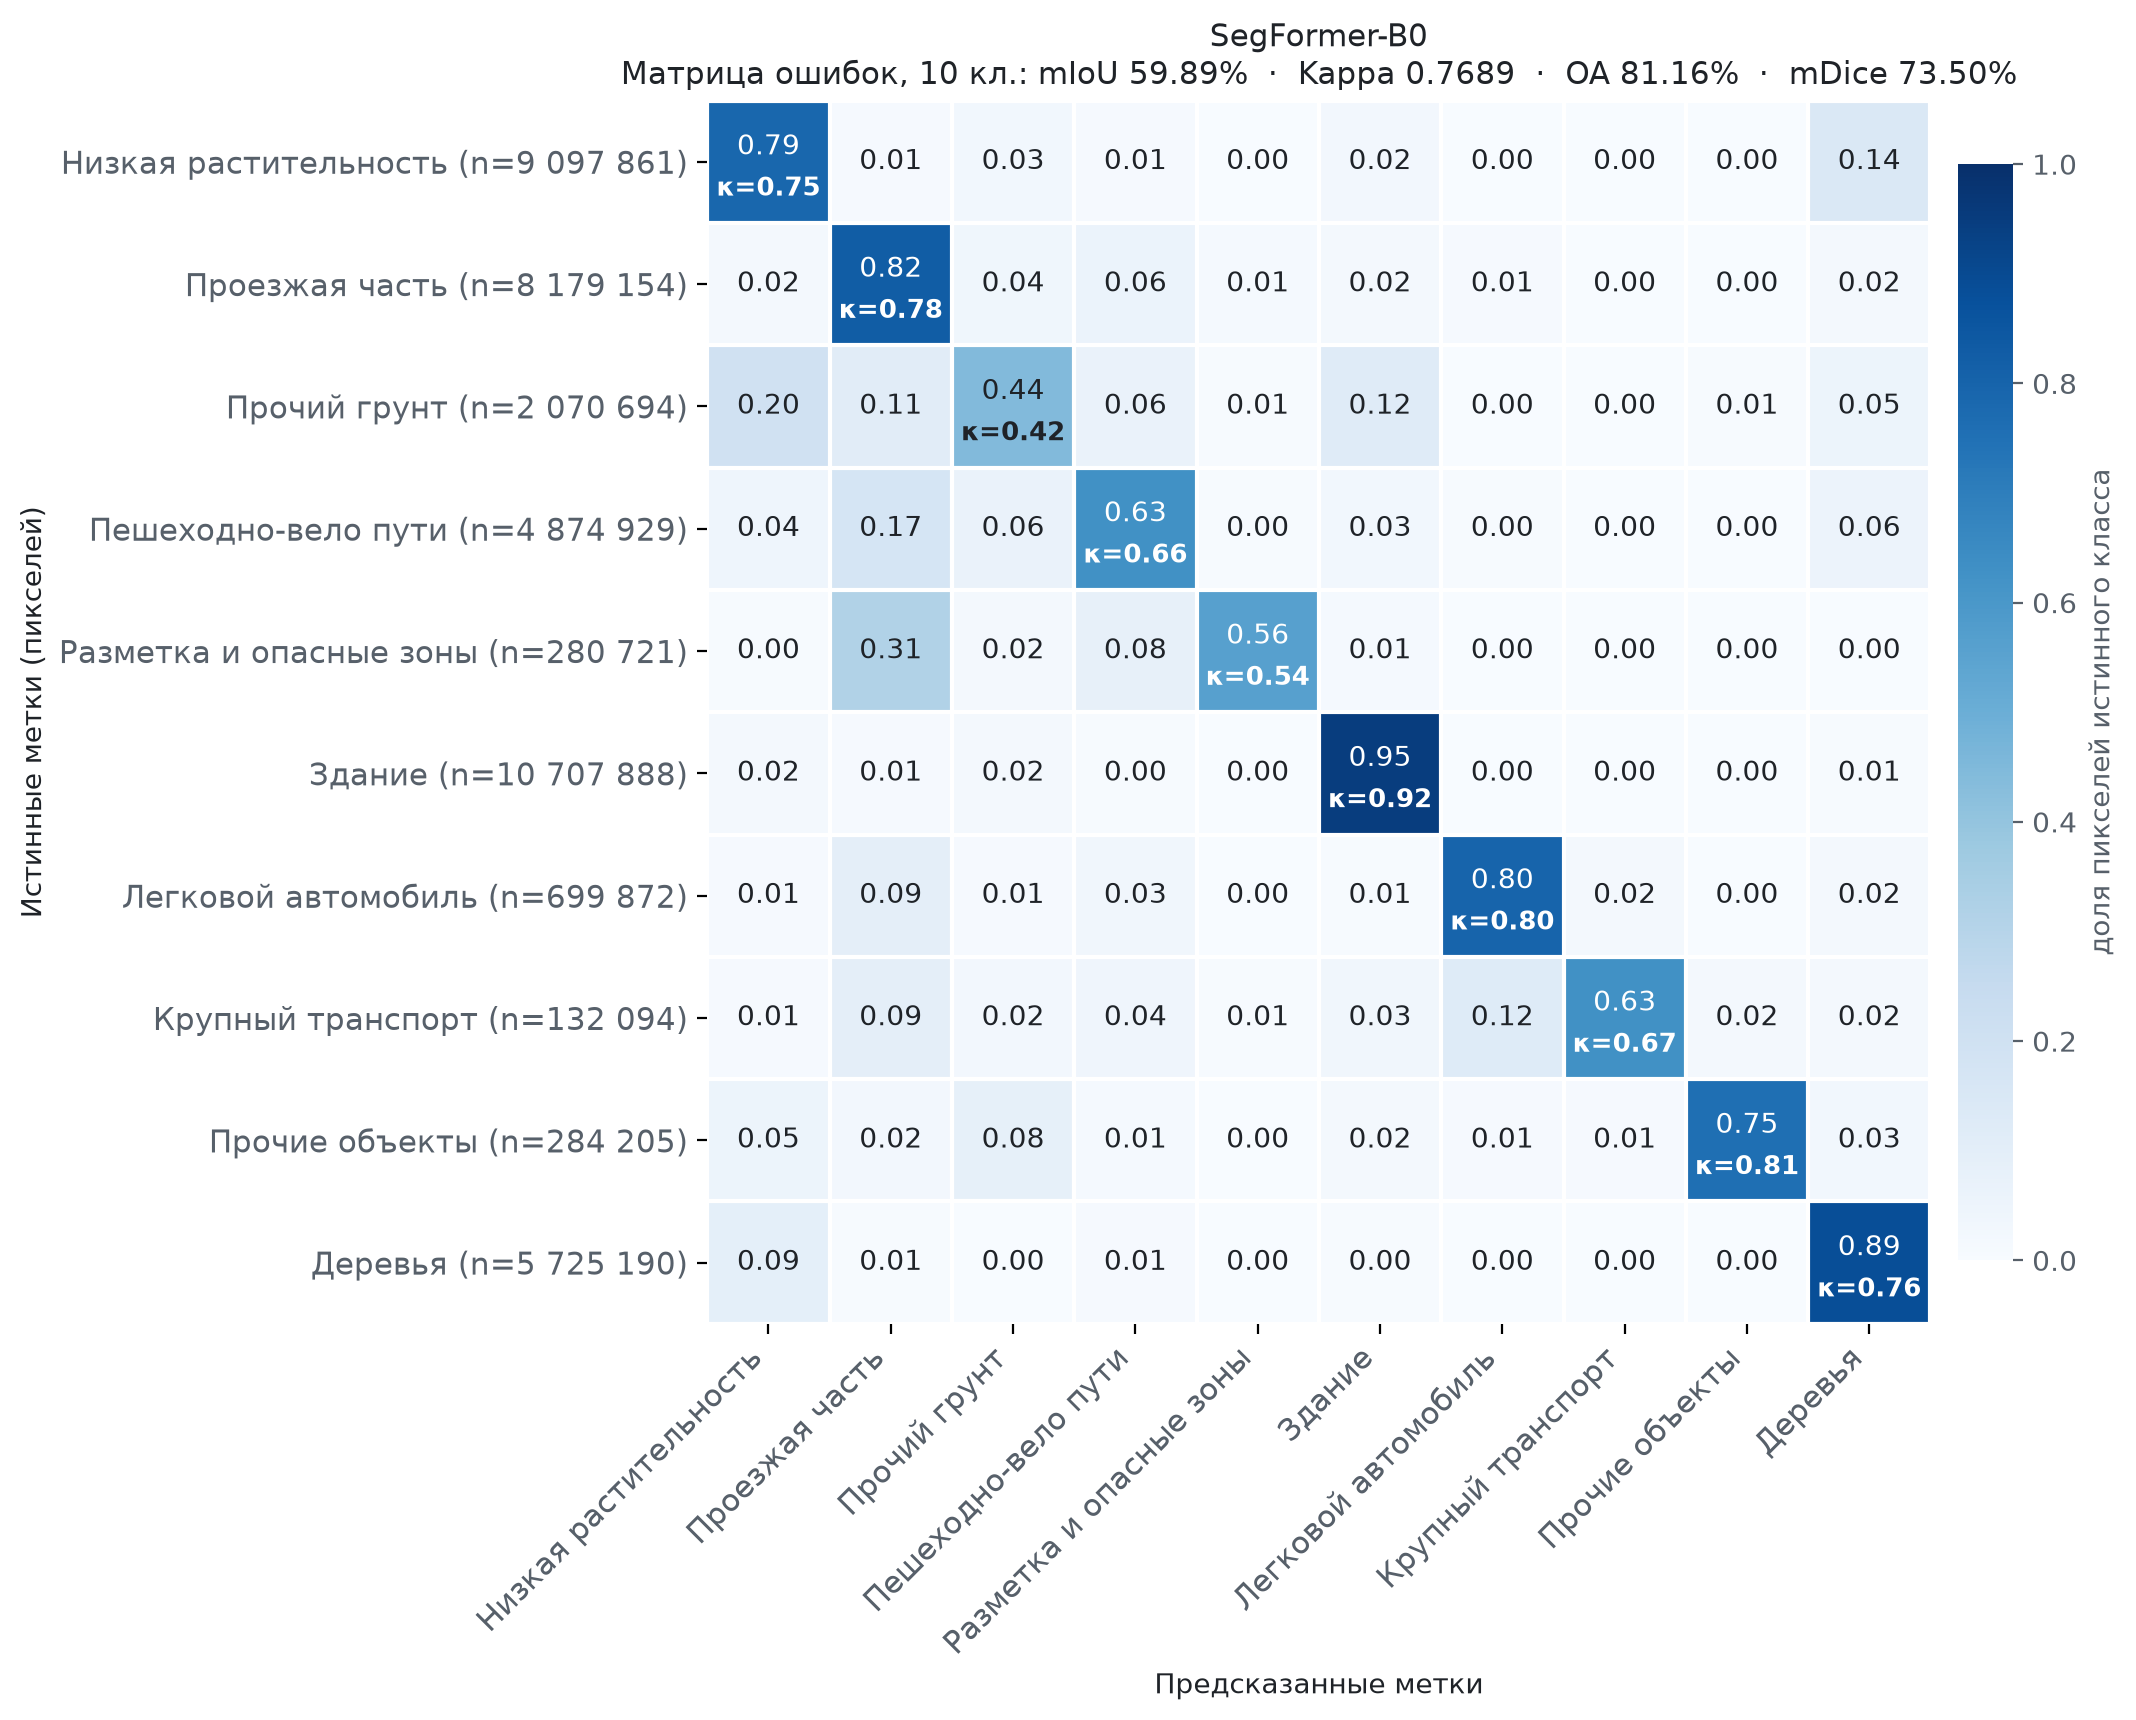

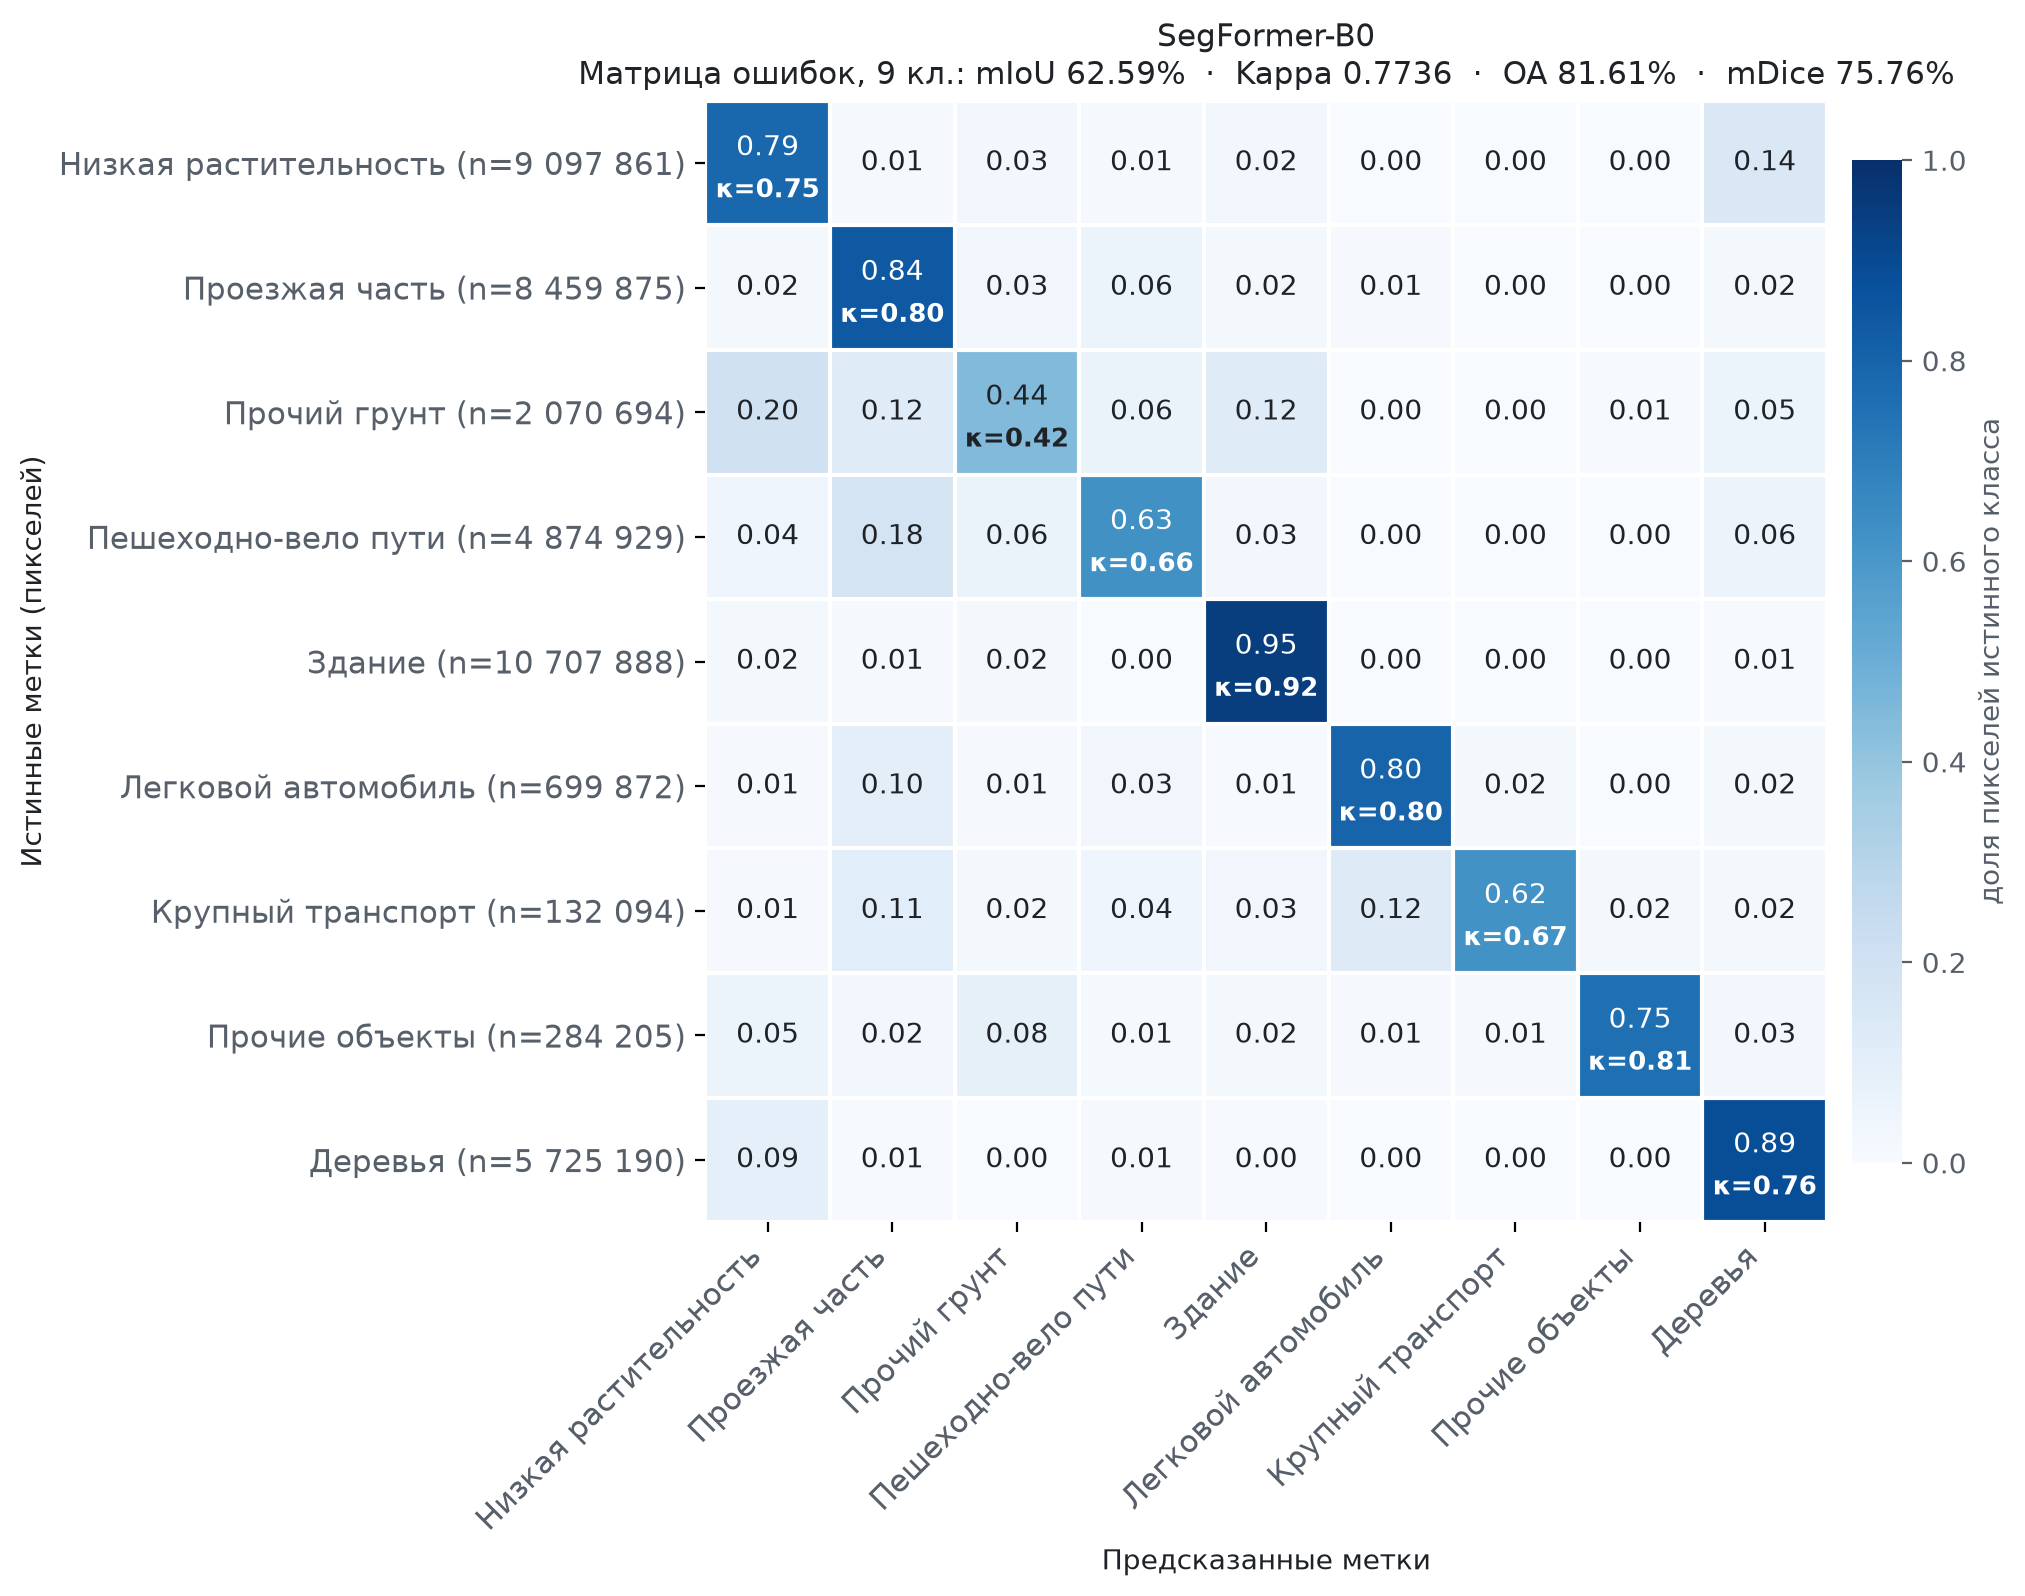

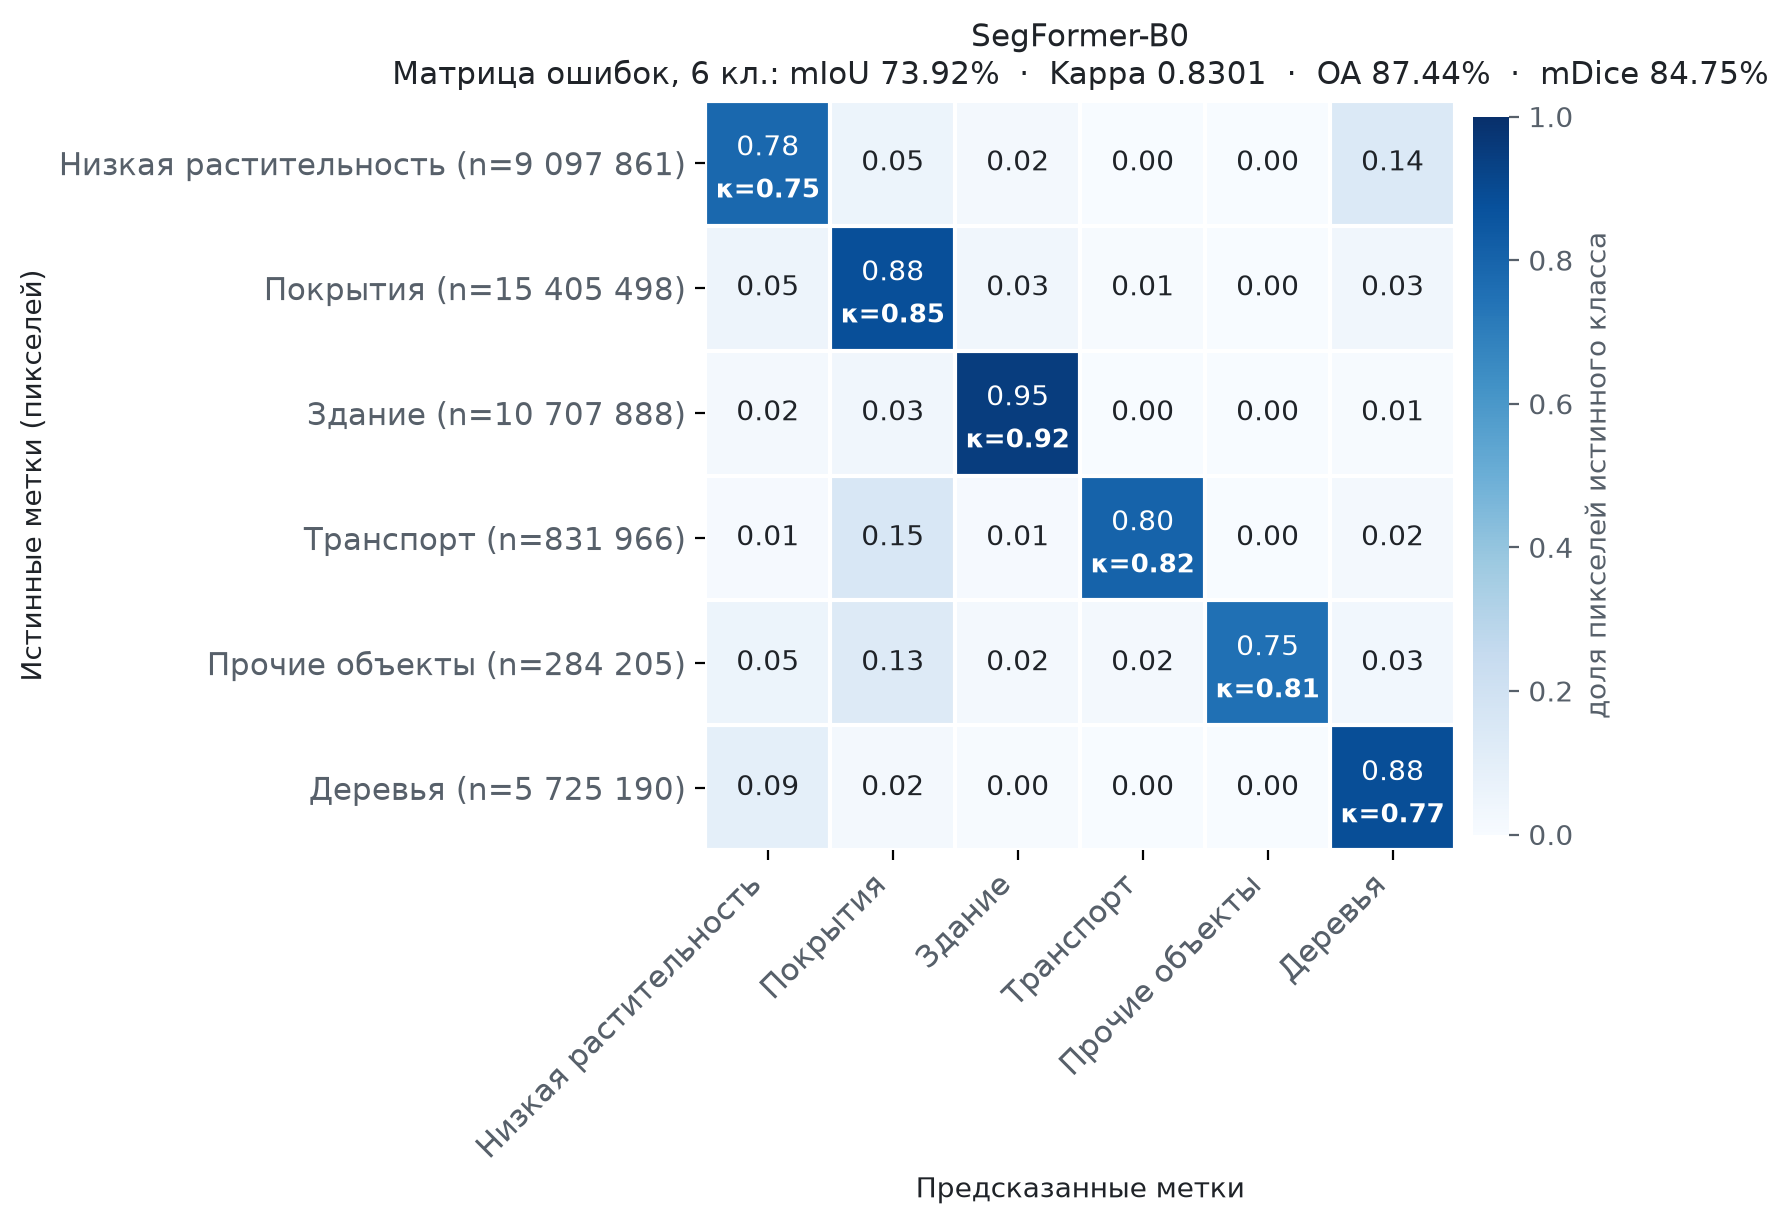

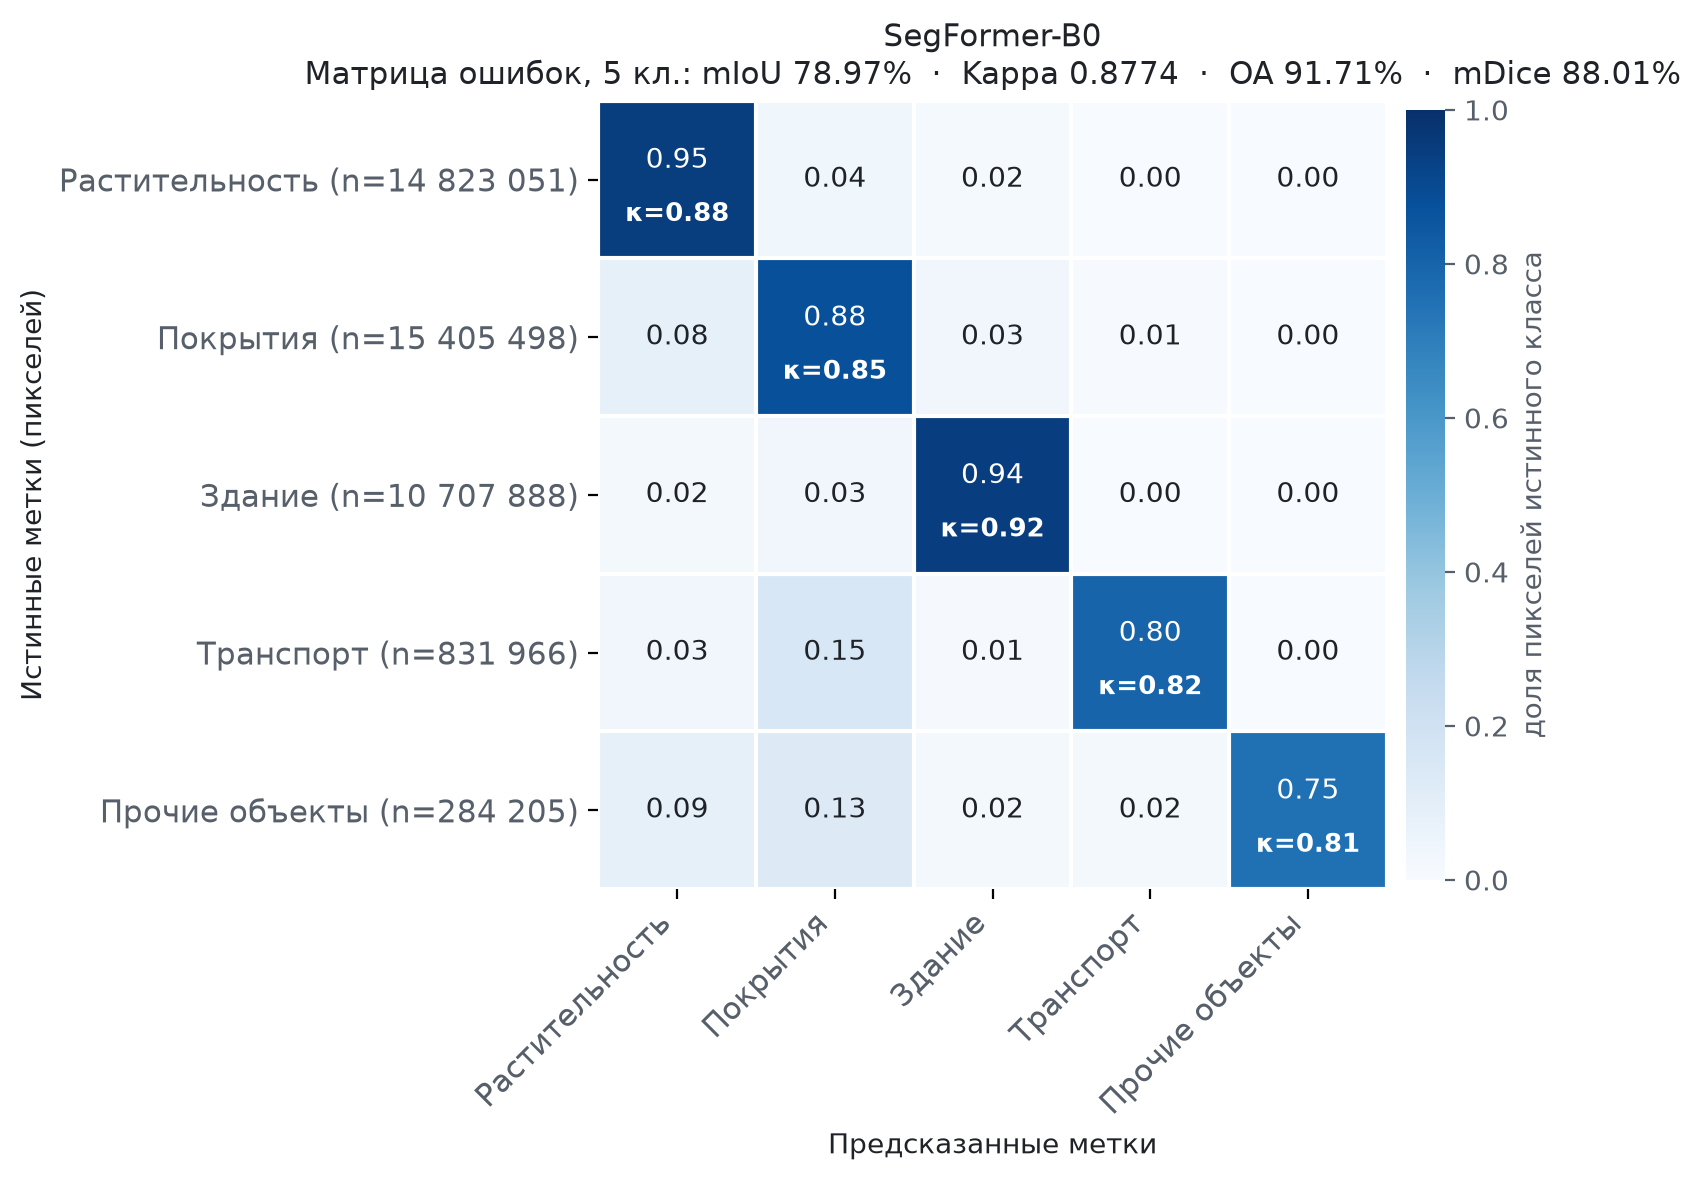

In [8]:
res = json.loads(Path(OUT_EVAL, 'eval.json').read_text())
f = res['flat']
print(f"20 классов: mIoU {f['mIoU']:.2f} %, mDice {f['mDice']:.2f} %, OA {f['aAcc']:.2f} %, kappa {f['kappa']/100:.4f}, val loss {f.get('val_loss', float('nan')):.3f}")
print('mIoU по числу классов:', {int(k[6:]): round(v, 1) for k, v in f.items() if k.startswith('mIoU_S') and k[6:].isdigit()})
for n in ('L0_20', 'S10', 'S9', 'S6', 'S5'):
    p = Path(OUT_EVAL, 'figures', f'cm_{n}.png')
    if p.exists():
        display(Image(str(p), width=950))

## **5. Обучение и дообучение**

Обучение включается параметром `TRAIN = True`. По умолчанию оно выключено, чтобы «Выполнить все» не запускало многочасовой процесс.

Начальные веса задаются параметром `INIT`:
* `'best'` — дообучение модели из релиза (эпоха 220);
* `'encoder'` — обучение заново, как в исходном эксперименте: кодировщик MiT-B0, предобученный на LoveDA, скачивается из релиза при первом запуске;
* `'/путь/к/checkpoint.pth'` — любая другая точка MMSeg.

Схема та же, что в эксперименте: патчи 1024 × 1024; эпоха — все ячейки сетки обучающих снимков и 25 % патчей с редкими классами (540 патчей); AdamW 6·10⁻⁵ с разогревом; fp16; проверка каждые `VAL_INTERVAL` эпох; снижение LR ×0,5 после 5 проверок без роста mIoU; остановка после 12. Лучшая модель сохраняется как `best_mIoU_epoch_N.pth` в папке запуска.

Если среда выполнения перезапустится без отключения сессии, повторный запуск ячейки с тем же `RUN_NAME` продолжит обучение с последней сохранённой точки. После завершения сессии диск очищается, поэтому лучшую модель скачайте кнопкой в разделе 8. На T4 одна эпоха занимает около 1,5 минуты.

In [9]:
TRAIN        = os.environ.get('SKY_TRAIN', '0') == '1'     # замените на True, чтобы обучать
INIT         = os.environ.get('SKY_INIT', 'best')
RUN_NAME     = os.environ.get('SKY_RUN', 'finetune_b0')
MAX_EPOCHS   = int(os.environ.get('SKY_MAX_EPOCHS', 600))
VAL_INTERVAL = int(os.environ.get('SKY_VAL_INTERVAL', 10))
BATCH        = int(os.environ.get('SKY_BATCH', 8))
WARMUP_ITERS = int(os.environ.get('SKY_WARMUP', 1500))
RUN_DIR = f'{WORK}/runs/{RUN_NAME}'
if TRAIN:
    run(PY, f'{BUNDLE}/scripts/train.py', '--cache', CACHE, '--work-dir', RUN_DIR, '--init', INIT, '--max-epochs', MAX_EPOCHS,
        '--val-interval', VAL_INTERVAL, '--batch', BATCH, '--warmup-iters', WARMUP_ITERS, '--progress-interval', 60)
else:
    print('обучение выключено (TRAIN = False)')

обучение выключено (TRAIN = False)


## **6. Оценка новой лучшей модели**

Лучший чекпойнт запуска (`best_mIoU_epoch_*.pth`) оценивается так же, как в разделе 4. Чтобы применить новую модель к снимкам, укажите его путь в `CHECKPOINT` раздела 3 или в `OWN_CHECKPOINT` раздела 7.

In [10]:
best = sorted(Path(RUN_DIR).glob('best_mIoU_epoch_*.pth'), key=lambda p: int(p.stem.split('_')[-1]))
if best:
    NEW_CKPT = str(best[-1]); print('лучшая модель запуска:', NEW_CKPT)
    OUT_EVAL_NEW = f'{RUN_DIR}/evaluation'
    run(PY, f'{BUNDLE}/scripts/evaluate.py', '--cache', CACHE, '--checkpoint', NEW_CKPT, '--out', OUT_EVAL_NEW, '--title', f'SegFormer-B0 ({RUN_NAME})')
else:
    print('в папке запуска нет лучшей модели: обучение не запускалось или не дошло до первой проверки')

в папке запуска нет лучшей модели: обучение не запускалось или не дошло до первой проверки


## **7. Инференс по своему снимку**

После запуска ячейки появится кнопка «Выбрать файлы»: выберите один или несколько снимков на компьютере. Подходят JPG/PNG/BMP/WEBP и растры GDAL — GeoTIFF, TIFF, JP2, IMG, VRT. Ожидаются 8-битные RGB-снимки с разрешением около 13 см, как в SkyScapes; 16-битные данные пересчитываются в 8 бит, номера каналов RGB задаются в `BANDS`.

Крупные растры (сотни мегабайт) удобнее положить в папку `/content/my_images` через панель «Файлы» слева и запустить ячейку с `UPLOAD = False`.

Маски сохраняются в `/content/skyscapes_segformer_runs/my_images` в тех же форматах, что в разделе 3; для GeoTIFF сохраняются проекция и привязка. Под снимками появится кнопка скачивания всех масок одним архивом.

In [15]:
UPLOAD         = True          # False — взять файлы, уже лежащие в /content/my_images
OWN_DIR        = f'{ROOT}/my_images'
OUT_OWN        = f'{WORK}/my_images'
OWN_CHECKPOINT = CHECKPOINT    # модель из релиза или свой best_mIoU_epoch_*.pth
OWN_SCHEMES    = '9 6 5'       # укрупнённые схемы, '' — не нужны
BANDS          = ''            # номера каналов R G B растра, например '1 2 3'; '' — первые три

import shutil
Path(OWN_DIR).mkdir(parents=True, exist_ok=True)
if UPLOAD and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        shutil.rmtree(OWN_DIR); Path(OWN_DIR).mkdir()
        for name, content in uploaded.items():
            Path(OWN_DIR, name).write_bytes(content)
elif os.environ.get('SKY_OWN_IMAGE'):                     # автоматическая проверка блокнота вне Colab
    shutil.copy(os.environ['SKY_OWN_IMAGE'], OWN_DIR)
own = sorted(p.name for p in Path(OWN_DIR).iterdir() if p.is_file())
print('снимки:', own if own else 'нет')
if own:
    args = ['--input', OWN_DIR, '--out', OUT_OWN, '--checkpoint', OWN_CHECKPOINT, '--conf']
    args += ['--schemes', *OWN_SCHEMES.split()] if OWN_SCHEMES else []
    args += ['--bands', *BANDS.split()] if BANDS else []
    run(PY, f'{BUNDLE}/scripts/infer.py', *args)

Saving 2012-04-26-Muenchen-Tunnel_4K0G0130.jpg to 2012-04-26-Muenchen-Tunnel_4K0G0130.jpg
снимки: ['2012-04-26-Muenchen-Tunnel_4K0G0130.jpg']
GPU Tesla T4: free 14.5 of 14.6 GB
/content/py311/lib/python3.11/site-packages/mmseg/models/builder.py:36: UserWarning: ``build_loss`` would be deprecated soon, please use ``mmseg.registry.MODELS.build()`` 
  warnings.warn('``build_loss`` would be deprecated soon, please use '
/content/py311/lib/python3.11/site-packages/mmseg/models/losses/cross_entropy_loss.py:250: UserWarning: Default ``avg_non_ignore`` is False, if you would like to ignore the certain label and average loss over non-ignore labels, which is the same with PyTorch official cross_entropy, set ``avg_non_ignore=True``.
  warnings.warn(
2012-04-26-Muenchen-Tunnel_4K0G0130.jpg: 5616x3744 -> masks in 7.1 s


2012-04-26-Muenchen-Tunnel_4K0G0110_preview.jpg


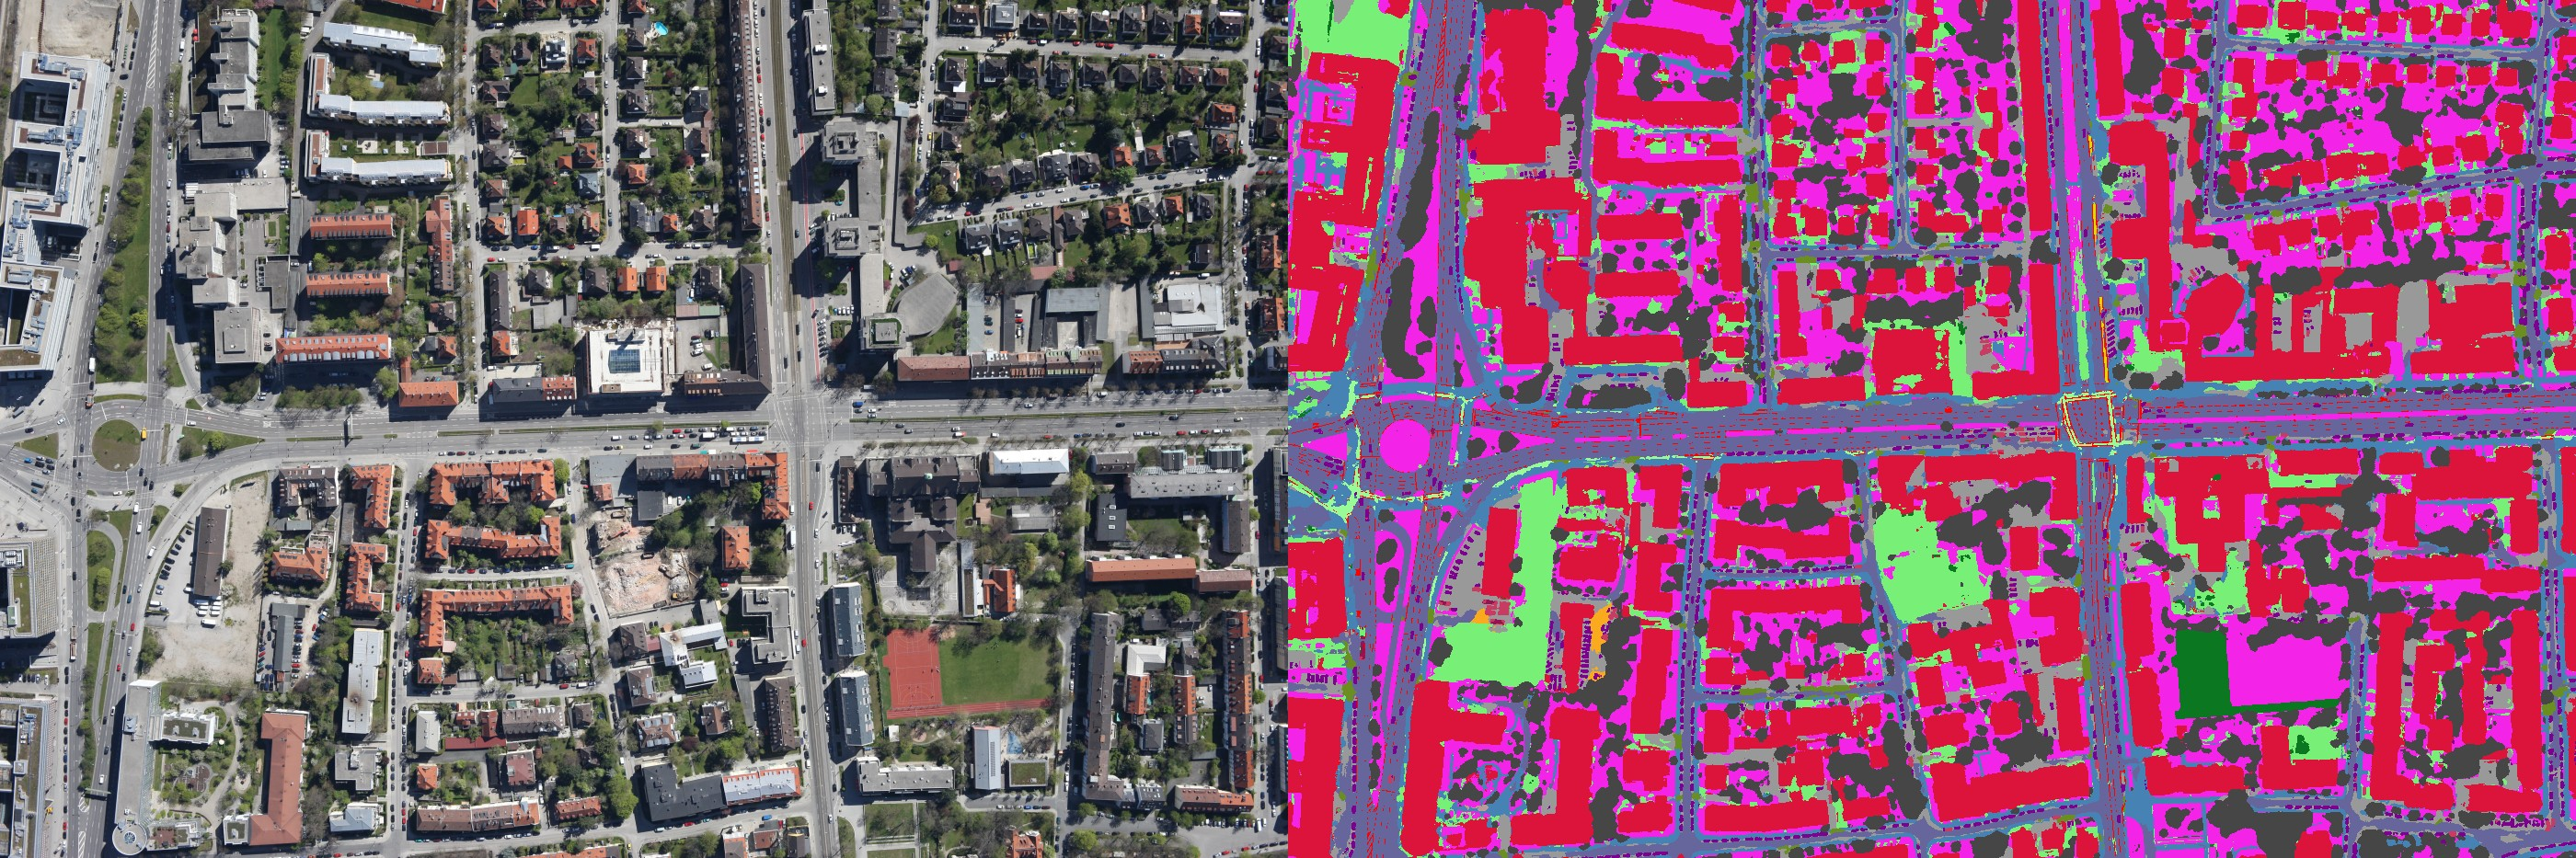

2012-04-26-Muenchen-Tunnel_4K0G0130_preview.jpg


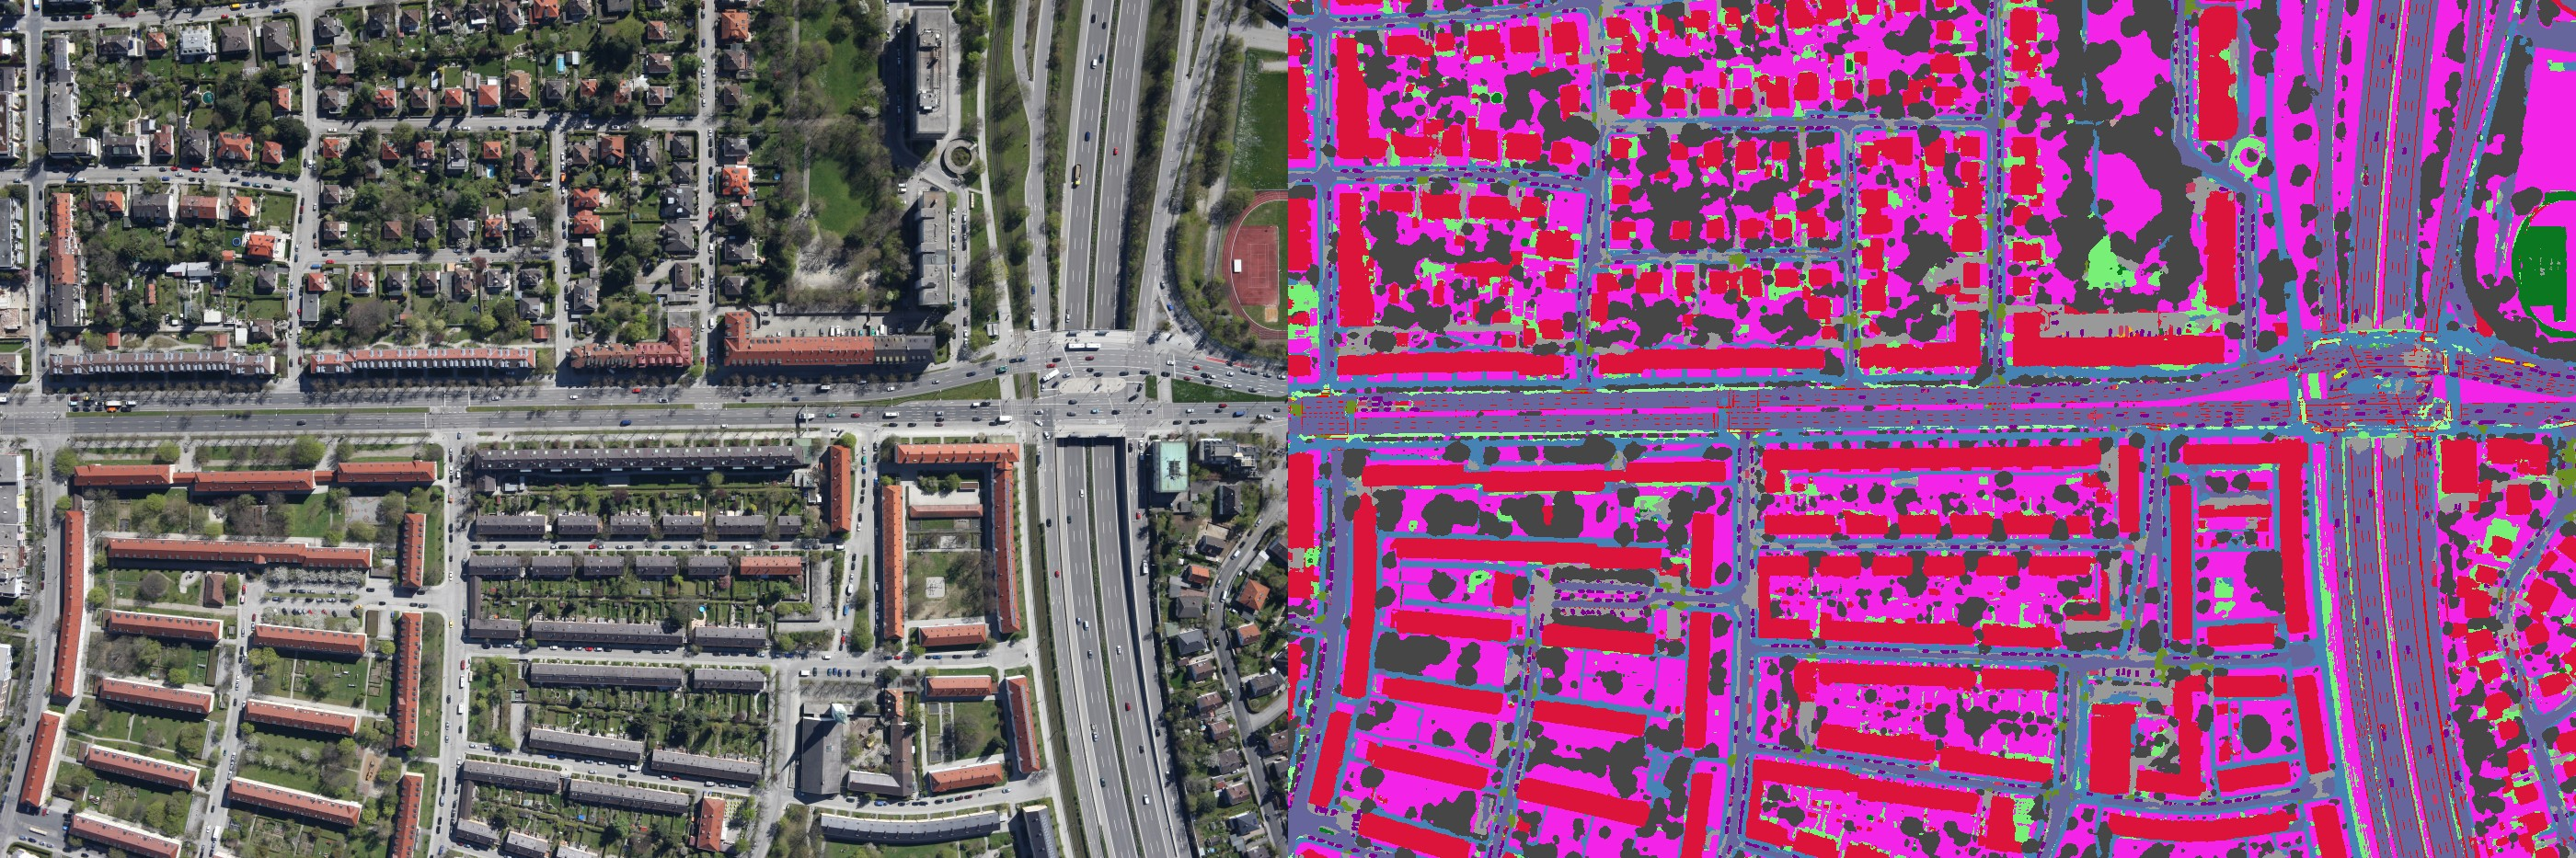

In [16]:
from IPython.display import Image, display
for p in sorted(Path(OUT_OWN).glob('*_preview.jpg')):
    print(p.name); display(Image(str(p), width=1100))
if any(Path(OUT_OWN).glob('*_classes*')):
    download_button('Скачать маски своих снимков (.zip)', lambda: zip_folder(OUT_OWN, 'my_images_masks'))

## **8. Скачать веса и результаты**

Кнопки ниже скачивают файлы с диска сессии на компьютер. Веса — чекпойнт MMSegmentation 1.2.2 (`state_dict` и метаданные классов); для работы с ним вне блокнота нужен пакет «Модель для MMSegmentation»: веса, конфигурация, модули `skyscapes_mmseg`, таблица классов, схема укрупнения и карточка модели.

Кнопка лучшей модели обучения появляется, если в разделе 5 было обучение. Архив результатов содержит маски, метрики, матрицы ошибок и папки запусков.

In [13]:
import zipfile


def model_package():
    # веса + всё, что нужно для работы с ними в MMSegmentation 1.2.2
    path = f'{ROOT}/segformer_b0_skyscapes_model.zip'
    names = ['checkpoints/segformer_b0_skyscapes_ep220.pth', 'configs/segformer_b0_skyscapes.py', 'splits/classes.json',
             'splits/merge_ladder.json', 'MODEL_CARD_RU.md', 'README.md']
    names += sorted(p.relative_to(BUNDLE).as_posix() for p in Path(BUNDLE, 'skyscapes_mmseg').glob('*.py'))
    with zipfile.ZipFile(path, 'w', zipfile.ZIP_DEFLATED, strict_timestamps=False) as z:
        for n in names:
            z.write(Path(BUNDLE, n), n)
    return path


download_button('Веса модели, эпоха 220 (.pth, 15 МБ)', lambda: CHECKPOINT)
download_button('Модель для MMSegmentation: веса, конфигурация, классы (.zip)', model_package)
runs_best = sorted(Path(WORK, 'runs').glob('*/best_mIoU_epoch_*.pth'), key=lambda p: p.stat().st_mtime)
if runs_best:
    download_button(f'Лучшая модель обучения: {runs_best[-1].parent.name}/{runs_best[-1].name}', lambda: str(runs_best[-1]))
download_button('Все результаты (.zip)', lambda: zip_folder(WORK, 'skyscapes_segformer_results'))

## **Примечания**

**Воспроизводимость.** Версии библиотек, код, конфигурация, веса и предобработка совпадают с экспериментом. На другой видеокарте (T4/L4/A100 вместо RTX 3090) логиты отличаются примерно на 10⁻³ из-за разных ядер cuDNN, на маске это единичные пиксели. Обучение между разными GPU побитово не воспроизводится (свойство CUDA), результат получается того же уровня.

**Память.** Обучение B0 с батчем 8 в fp16 занимает около 10 ГБ видеопамяти; для GPU с меньшим объёмом уменьшите `BATCH`.

**Пакет** клонируется в `/content/skyscapes_segformer`: `configs/` — конфигурация MMSeg; `skyscapes_mmseg/` — датасет, аугментации, метрики и хуки; `scripts/` — загрузка файлов релиза и набора, подготовка данных, обучение, оценка, инференс, матрицы ошибок, загрузка кодировщика; `checkpoints/` — скачанные веса; `env/` — установка и проверка окружения, список файлов релиза с контрольными суммами (`assets.json`); `splits/` — классы и схема укрупнения. Скрипты можно запускать и без блокнота (см. `README.md`).